# Clasificación de textos en Esperanto: tenis, baloncesto y rugby

**Minería de Textos · 4º INF-A · CUNEF · Curso 2026/2027** — Práctica de programación

**Equipo:** Lucía Martínez, Borja Higuero y Gonzalo Vaca

---

Este cuaderno construye **de principio a fin** un sistema que clasifica textos en Esperanto según su temática deportiva:

| Clase (etiqueta) | Deporte | Por qué es un problema no trivial |
|---|---|---|
| `teniso` | Tenis | Comparte con los otros dos el vocabulario de competición: *turniro, matĉo, ĉampiono, ludanto, venki...* |
| `korbopilkado` | Baloncesto | En Esperanto conviven dos nombres (*korbopilkado* y el préstamo *basketbalo*) |
| `rugbeo` | Rugby | Es la clase con menos artículos en la Wikipedia en Esperanto |

Las tres categorías son **semánticamente cercanas** (todas son deportes de pelota con ligas, torneos, jugadores y resultados), que es lo que pide el enunciado para que la clasificación no sea trivial.

### Índice

1. [Configuración](#config)
2. [Fase 1 — Dataset](#fase1): API de Wikipedia, *web crawling* por categorías, limpieza en párrafos, contrato de datos y medida del ruido.
3. [Fase 2 — Modelo NLP para Esperanto](#fase2): tokenizador, segmentador, etiquetador POS + morfología, lematizador y *stop-words*, con API tipo spaCy (`nlp(texto)` → `Doc` → `Token`).
4. [Fase 3 — Clasificación](#fase3): vectorización (BoW, TF-IDF clásico y el TF-IDF por clases visto en clase), selección de modelo con validación cruzada y evaluación (accuracy, F1 macro, matriz de confusión).
5. [Clasificación de páginas web reales](#web): *web scraping* con `requests` + `BeautifulSoup` y probabilidad de cada categoría.
6. [Conclusiones](#conclusiones)


<a id="config"></a>
## 1. Configuración

Parámetros de ejecución en un único lugar. Los más importantes:

* `GENERAR_DATASET`: si es `False` (por defecto) se descarga el dataset ya generado y publicado en GitHub (**ejecución asíncrona**, apartado 4.1.4 del enunciado). Si es `True`, o si la descarga falla, el cuaderno lo **regenera** desde la API de Wikipedia (tarda unos minutos).
* `SEED`: semilla para que todos los resultados (particiones, modelos) sean reproducibles.

In [1]:
# ---- Librerías (todas vistas en clase; vienen instaladas en Google Colab) ----
import io
import re
import sys
import json
import time
import random
import platform
import unicodedata
from collections import Counter
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser

import numpy as np
import pandas as pd
import requests
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from bs4 import BeautifulSoup

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     StratifiedGroupKFold, cross_val_score,
                                     cross_val_predict, GridSearchCV)
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# ---- Parámetros de ejecución ----
GENERAR_DATASET = False          # True -> regenerar desde Wikipedia (5-10 min)

# Repositorio público donde está publicado el dataset (Fase 1).
GITHUB_USUARIO = "luuciaamartinez"
GITHUB_REPO = "mineria-textos-esperanto"
GITHUB_RAMA = "main"
RUTA_CSV = "dataset_deportes_eo.csv"            # contrato: text;class
RUTA_META = "dataset_deportes_eo_meta.csv"      # metadatos (artículo, fuente)


def urls_github(ruta):
    """El mismo fichero servido por dos hosts distintos (GitHub y su CDN
    jsDelivr): si uno falla, se prueba el otro."""
    return [
        f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{GITHUB_REPO}/{GITHUB_RAMA}/{ruta}",
        f"https://cdn.jsdelivr.net/gh/{GITHUB_USUARIO}/{GITHUB_REPO}@{GITHUB_RAMA}/{ruta}",
    ]


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---- Estilo de las gráficas: un color fijo por clase en todo el cuaderno ----
COLORES = {"teniso": "#2a78d6", "korbopilkado": "#eb6834", "rugbeo": "#1baf7a"}
NOMBRES = {"teniso": "Tenis", "korbopilkado": "Baloncesto", "rugbeo": "Rugby"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 140)

T_INICIO = time.perf_counter()
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | requests {requests.__version__} | "
      f"matplotlib {matplotlib.__version__}")

Python 3.13.16 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | requests 2.32.4 | matplotlib 3.10.0


<a id="fase1"></a>
# 2. Fase 1 — Dataset

**Objetivo:** obtener de forma automática y reproducible un dataset etiquetado de párrafos en Esperanto (`text;class`) sobre las tres temáticas.

### 2.1 Elección de temáticas y estudio de viabilidad

Antes de fijar las categorías se exploró la Wikipedia en Esperanto (*Vikipedio*) con su API, como recomienda el enunciado. Lo que se encontró condicionó varias decisiones:

* **Golf se descartó.** Era la idea inicial, pero apenas da ~160 párrafos útiles, y además *golfo* en Esperanto significa también "golfo" geográfico (*Golfo de Biskajo*), lo que mete muchísimo ruido en las búsquedas. Se sustituyó por **baloncesto**.
* **Baloncesto no está donde se espera.** `Kategorio:Basketbalo` no existe: la categoría real es `Kategorio:Korbopilkado` ("juego de la pelota-cesta"), aunque en los textos también aparece *basketbalo*. Por eso la etiqueta es `korbopilkado` y la búsqueda incluye ambos nombres.
* **Rugby es la clase pequeña.** `Kategorio:Rugbeo` solo tiene 17 artículos, y de su subcategoría cuelga `Usona piedpilko` (fútbol americano), que **no** es rugby y se excluye.

### 2.2 Estrategia de obtención de datos

1. **Web crawling por categorías (BFS).** Para cada clase se parte de su categoría raíz y se recorren sus subcategorías hasta `PROFUNDIDAD_MAX = 3` niveles, recogiendo todos los artículos. Cada párrafo **hereda la etiqueta del artículo**.
2. **Completar las clases pequeñas con la búsqueda del API.** Si una clase no llega a `OBJETIVO_PARRAFOS`, se usa `list=search` con términos de la temática. Como esos artículos *no* son del deporte (p. ej. la página de una ciudad que tiene un equipo de rugby), de ellos **solo se aceptan los párrafos que mencionan la temática** (palabra clave) y no la de otra clase.
3. **Párrafos limpios.** Se usa `prop=extracts&explaintext=1`, que devuelve el texto ya sin HTML, plantillas ni referencias. Después se eliminan secciones sin contenido (*Referencoj, Eksteraj ligiloj, Vidu ankaŭ*...), restos de enlaces/referencias, el carácter `;` (lo exige el contrato) y párrafos que no son prosa (listas de resultados, tablas, texto en inglés).
4. **Ética del scraping** (tema 3.4): User-Agent identificativo, pausa entre peticiones, parámetro `maxlag` y reintentos con espera exponencial para no sobrecargar los servidores.

Además se **reserva** un artículo (`Ĉampioneco de Ses Nacioj`) que no entra en el dataset, para poder usarlo después como página web de prueba nunca vista por el modelo.

In [2]:
# =============================================================================
# FASE 1 · Parámetros
# =============================================================================
API_URL = "https://eo.wikipedia.org/w/api.php"
# Wikimedia exige que cada cliente se identifique con un User-Agent propio que
# incluya una forma de contacto (URL o email); si no, responde 403 Forbidden.
HEADERS = {"User-Agent": (f"CUNEF-MineriaTextos-Practica/1.0 "
                          f"(https://github.com/{GITHUB_USUARIO}/{GITHUB_REPO}; practica universitaria) "
                          f"python-requests/{requests.__version__}")}

CATEGORIAS = {
    "teniso": {
        "raiz": "Kategorio:Teniso",
        "busqueda": ["teniso", "tenisisto", "tenisejo", "tenisa"],
        "clave": r"tenis",
    },
    "korbopilkado": {
        "raiz": "Kategorio:Korbopilkado",
        "busqueda": ["korbopilkado", "korbopilkisto", "korbopilka",
                     "korbopilkteamo", "basketbalo", "NBA"],
        "clave": r"korbopilk|basketbal|\bNBA\b",
    },
    "rugbeo": {
        "raiz": "Kategorio:Rugbeo",
        "busqueda": ["rugbeo", "rugbeisto", "rugbea", "rugbeteamo",
                     "rugbeklubo", "rugbeludanto"],
        "clave": r"rugbe",
    },
}
PROFUNDIDAD_MAX = 3            # niveles de subcategorías que se recorren
EXCLUIR_SUBCATEGORIAS = ["videolud", "Usona piedpilko"]   # ramas que no son la temática
OBJETIVO_PARRAFOS = 400        # por debajo, la clase se completa con búsqueda
MAX_RESULTADOS_BUSQUEDA = 300  # resultados por término de búsqueda
MAX_PAGINAS_BUSQUEDA = 300     # artículos de búsqueda por clase
MIN_PALABRAS, MIN_CARACTERES = 10, 60
PAGINAS_RESERVADAS_TEST = {"Ĉampioneco de Ses Nacioj"}   # no entran en el dataset

SECCIONES_IGNORADAS = {
    "referencoj", "notoj", "piednotoj", "fontoj", "eksteraj ligiloj",
    "ligiloj", "vidu ankaŭ", "rilataj artikoloj", "literaturo",
    "bibliografio", "galerio", "eksteraj referencoj", "notoj kaj referencoj",
}
# Palabras funcionales muy frecuentes del Esperanto: si un párrafo casi no las
# tiene, no es prosa en Esperanto (es una lista, una tabla o texto en inglés).
FUNCIONALES_EO = {"la", "de", "kaj", "en", "estis", "estas", "al", "kun",
                  "por", "li", "ŝi", "ĝi", "ili", "kiu", "kiuj", "sed", "el",
                  "post", "dum", "ke", "pri", "per", "sur", "ankaŭ", "unu"}

### 2.3 Acceso al API de Wikipedia

Funciones de bajo nivel, cada una con una única responsabilidad (tema 3.6, APIs REST con `requests`):

| Función | Llamada al API | Qué devuelve |
|---|---|---|
| `api_get` | cualquiera | JSON de la respuesta, con reintentos |
| `miembros_categoria` | `list=categorymembers` | artículos o subcategorías de una categoría (paginando con `continue`) |
| `recorrer_categoria` | — | *crawler* BFS por el árbol de categorías |
| `buscar_titulos` | `list=search` | títulos de la búsqueda de texto completo |
| `obtener_extracto` | `prop=extracts` | texto plano del artículo |

In [3]:
SESSION = requests.Session()   # reutiliza la conexión TCP entre peticiones


def api_get(params, reintentos=5, pausa=0.1):
    """GET al API de MediaWiki con reintentos y espera exponencial.

    - `formatversion=2`: respuestas JSON más simples (listas en vez de dicts por id).
    - `maxlag=5`: si los servidores van cargados, el API nos pide esperar.
    - `pausa`: espera entre peticiones para no saturar el servidor.
    Lanza ConnectionError si tras todos los reintentos no hay respuesta válida.
    """
    params = {"format": "json", "formatversion": "2", "maxlag": "5", **params}
    ultimo_error = None
    for intento in range(reintentos):
        try:
            r = SESSION.get(API_URL, params=params, headers=HEADERS, timeout=20)
            if r.status_code == 200:
                datos = r.json()
                if "error" not in datos:
                    time.sleep(pausa)
                    return datos
                ultimo_error = datos["error"].get("code")
            else:
                ultimo_error = f"HTTP {r.status_code}"
        except (requests.RequestException, ValueError) as e:
            ultimo_error = type(e).__name__
        time.sleep(2 ** intento)            # 1, 2, 4, 8, 16 s
    raise ConnectionError(f"API de Wikipedia no disponible ({ultimo_error})")


def miembros_categoria(categoria, tipo):
    """Títulos de una categoría. tipo='page' (artículos) o 'subcat'."""
    titulos, cont = [], {}
    while True:
        datos = api_get({"action": "query", "list": "categorymembers",
                         "cmtitle": categoria, "cmtype": tipo,
                         "cmlimit": "500", **cont})
        for m in datos.get("query", {}).get("categorymembers", []):
            if tipo != "page" or m.get("ns") == 0:      # ns=0: artículos
                titulos.append(m["title"])
        if "continue" not in datos:
            return titulos
        cont = datos["continue"]                         # siguiente página


def recorrer_categoria(raiz, profundidad=PROFUNDIDAD_MAX, excluir=EXCLUIR_SUBCATEGORIAS):
    """Web crawling en anchura (BFS) por el árbol de categorías.

    Devuelve los artículos encontrados (sin repetir, en orden de visita) y las
    categorías visitadas. `excluir` poda ramas que no son la temática.
    """
    vistas, frontera = {raiz}, [raiz]
    paginas, vistas_pag = [], set()
    for nivel in range(profundidad + 1):
        siguiente = []
        for cat in frontera:
            for t in miembros_categoria(cat, "page"):
                if t not in vistas_pag:
                    vistas_pag.add(t)
                    paginas.append(t)
            if nivel < profundidad:
                for sub in miembros_categoria(cat, "subcat"):
                    if sub not in vistas and not any(
                            e.lower() in sub.lower() for e in excluir):
                        vistas.add(sub)
                        siguiente.append(sub)
        frontera = siguiente
        if not frontera:
            break
    return paginas, sorted(vistas)


def buscar_titulos(termino, maximo=MAX_RESULTADOS_BUSQUEDA):
    """Búsqueda de texto completo del API (list=search), paginada de 100 en 100."""
    titulos, offset = [], 0
    while offset < maximo:
        datos = api_get({"action": "query", "list": "search", "srsearch": termino,
                         "srnamespace": "0", "srlimit": "100",
                         "sroffset": str(offset)})
        titulos += [r["title"] for r in datos.get("query", {}).get("search", [])]
        if "continue" not in datos:
            break
        offset = datos["continue"]["sroffset"]
    return titulos


def obtener_extracto(titulo):
    """Texto plano de un artículo (prop=extracts + explaintext: sin HTML,
    sin plantillas y sin marcas de referencia). '' si no existe."""
    datos = api_get({"action": "query", "prop": "extracts", "explaintext": "1",
                     "titles": titulo, "redirects": "1"})
    paginas = datos.get("query", {}).get("pages", [])
    if not paginas or paginas[0].get("missing"):
        return ""
    return paginas[0].get("extract", "") or ""

### 2.4 Del artículo a párrafos limpios

`explaintext` devuelve el artículo con un párrafo por línea y los títulos de sección como `== Historio ==`. A partir de ahí:

* `parrafos_de_articulo` recorre las líneas, sabe en qué sección está y salta las secciones no informativas.
* `limpiar_parrafo` normaliza Unicode (NFC, importante por los diacríticos *ĉ ĝ ĥ ĵ ŝ ŭ*), quita caracteres invisibles, enlaces, marcas tipo `[1]`, restos de HTML y paréntesis vacíos, y **sustituye `;` por `,`** (contrato de datos).
* `es_parrafo_valido` aplica el filtro de calidad: mínimo de palabras y caracteres, mayoría de letras (descarta listas como `6–3, 7–5, 6–4`) y al menos dos palabras funcionales del Esperanto (descarta títulos y frases en inglés).

In [4]:
_TITULO_SECCION = re.compile(r"^(={2,6})\s*(.+?)\s*\1\s*$")
_INVISIBLES = re.compile(r"[​-‏‪-‮⁠﻿\xad]")


def limpiar_parrafo(p):
    """Limpia un párrafo de texto plano (también se usa con texto web)."""
    p = unicodedata.normalize("NFC", p)
    p = _INVISIBLES.sub("", p)
    p = re.sub(r"(https?://|www\.)\S+", " ", p)                              # enlaces
    p = re.sub(r"\[\s*(\d+|[a-z]|noto \d+|citaĵo bezonata)\s*\]", " ", p)    # [1], [a]
    p = re.sub(r"<[^>]+>", " ", p)                                          # restos HTML
    p = re.sub(r"\(\s*[,;:]?\s*\)", " ", p)                                 # ( ) vacíos
    p = p.replace(";", ",")                                                 # contrato
    p = re.sub(r"\s+", " ", p).strip()
    p = re.sub(r"\s+([,.:)])", r"\1", p)
    return p


def es_parrafo_valido(p, min_palabras=MIN_PALABRAS, min_caracteres=MIN_CARACTERES):
    """Filtro de calidad: longitud mínima, mayoría de letras y prosa en Esperanto."""
    palabras = p.split()
    if len(palabras) < min_palabras or len(p) < min_caracteres:
        return False
    if sum(c.isalpha() for c in p) / len(p) < 0.6:      # listas de resultados, tablas
        return False
    funcionales = sum(w.lower().strip(",.()") in FUNCIONALES_EO for w in palabras)
    return funcionales >= 2


def parrafos_de_articulo(texto):
    """Divide un extracto en párrafos válidos, ignorando secciones no informativas."""
    resultado, seccion = [], ""
    for linea in texto.split("\n"):
        m = _TITULO_SECCION.match(linea.strip())
        if m:
            if len(m.group(1)) == 2:           # solo las secciones de primer nivel
                seccion = m.group(2).strip().lower()
            continue
        if seccion in SECCIONES_IGNORADAS:
            continue
        p = limpiar_parrafo(linea)
        if es_parrafo_valido(p):
            resultado.append(p)
    return resultado


# --- Demostración con un extracto inventado que tiene todos los casos ---
ejemplo = """Teniso estas sporto ludata per rakedo kaj pilko‏; ĝi naskiĝis en Anglio[1].
== Historio ==
La moderna teniso estis inventita en la 19-a jarcento kaj rapide disvastiĝis en la mondo ( ).
6–3, 7–5, 6–4
== Eksteraj ligiloj ==
Oficiala retejo de la ITF: https://www.itftennis.com kaj aliaj ligiloj al la temo."""
for p in parrafos_de_articulo(ejemplo):
    print("✔", p)

✔ Teniso estas sporto ludata per rakedo kaj pilko, ĝi naskiĝis en Anglio.
✔ La moderna teniso estis inventita en la 19-a jarcento kaj rapide disvastiĝis en la mondo.


### 2.5 Construcción del dataset

`construir_dataset` encadena todo. Decisiones para controlar el ruido de etiquetado:

* Un artículo que aparece en categorías de **dos clases** es ambiguo y se descarta.
* De los artículos obtenidos por **búsqueda** solo se guardan párrafos con la palabra clave de su clase y sin la de otra.
* Un párrafo **duplicado** (p. ej. repetido en dos artículos o en dos clases) se elimina por completo.
* Si falla la descarga de un artículo concreto se registra y se sigue; si fallan demasiados, se aborta para no generar un dataset sesgado.

Además de `text` y `class`, se guardan metadatos (`titulo`, `fuente`, `tiene_clave`) que servirán para **medir el ruido** y para evaluar sin fugas entre artículos. Estos metadatos van en un fichero aparte para que el CSV principal cumpla exactamente el contrato.

In [5]:
def construir_dataset(categorias=CATEGORIAS, verbose=True):
    """Pipeline completo de la Fase 1. Devuelve un DataFrame con:
    text, class, titulo, fuente ('categoria' / 'busqueda'), tiene_clave."""
    log = print if verbose else (lambda *a, **k: None)
    claves = {c: re.compile(cfg["clave"], re.IGNORECASE) for c, cfg in categorias.items()}
    t0 = time.perf_counter()

    # 1) Crawling de categorías
    paginas_cat = {}
    for clase, cfg in categorias.items():
        paginas, cats = recorrer_categoria(cfg["raiz"])
        paginas_cat[clase] = [p for p in paginas if p not in PAGINAS_RESERVADAS_TEST]
        log(f"[{clase}] {len(cats)} categorías recorridas, {len(paginas)} artículos")

    # Artículos presentes en categorías de varias clases -> ambiguos
    conteo = Counter(t for ps in paginas_cat.values() for t in set(ps))
    ambiguos = {t for t, n in conteo.items() if n > 1}
    todos_cat = set(conteo)
    log(f"Artículos en varias clases (descartados): {len(ambiguos)} {sorted(ambiguos)[:5]}")

    filas, fallos = [], []

    def anadir(clase, titulo, fuente, solo_con_clave):
        try:
            texto = obtener_extracto(titulo)
        except ConnectionError:
            fallos.append(titulo)
            return
        for p in parrafos_de_articulo(texto):
            propia = bool(claves[clase].search(p))
            otra = any(claves[o].search(p) for o in claves if o != clase)
            if solo_con_clave and (not propia or otra):
                continue
            filas.append({"text": p, "class": clase, "titulo": titulo,
                          "fuente": fuente, "tiene_clave": propia})

    # 2) Párrafos de los artículos de cada categoría (etiqueta heredada)
    for clase, paginas in paginas_cat.items():
        for titulo in paginas:
            if titulo not in ambiguos:
                anadir(clase, titulo, "categoria", solo_con_clave=False)

    # 3) Clases con pocos párrafos -> completar con la búsqueda del API
    for clase, cfg in categorias.items():
        n = sum(f["class"] == clase for f in filas)
        if n >= OBJETIVO_PARRAFOS:
            log(f"[{clase}] {n} párrafos de categoría: no necesita búsqueda")
            continue
        candidatos = list(dict.fromkeys(
            t for termino in cfg["busqueda"] for t in buscar_titulos(termino)))
        candidatos = [t for t in candidatos[:MAX_PAGINAS_BUSQUEDA]
                      if t not in todos_cat and t not in PAGINAS_RESERVADAS_TEST]
        log(f"[{clase}] {n} párrafos de categoría -> búsqueda en {len(candidatos)} artículos más")
        for titulo in candidatos:
            anadir(clase, titulo, "busqueda", solo_con_clave=True)

    total = sum(len(v) for v in paginas_cat.values())
    if fallos and len(fallos) > 0.5 * total:
        raise ConnectionError(f"Fallaron {len(fallos)} artículos: dataset no fiable")
    if fallos:
        log(f"Artículos que no se pudieron descargar (omitidos): {len(fallos)}")

    df = pd.DataFrame(filas)
    antes = len(df)
    df = df.drop_duplicates(subset="text", keep=False).reset_index(drop=True)
    log(f"Párrafos duplicados eliminados: {antes - len(df)}")
    log(f"Tiempo de generación: {time.perf_counter() - t0:.0f} s")
    return df

### 2.6 Ejecución asíncrona: cargar el dataset publicado o generarlo

Generar el dataset supone unas 700 peticiones al API, así que se generó una vez y se publicó en GitHub. Esta celda sigue este orden, de modo que **el cuaderno sobrevive a la caída de cualquiera de las webs**:

1. Si `GENERAR_DATASET = False`: descargar el CSV de GitHub (`raw.githubusercontent.com`) y, si falla, de su espejo en `cdn.jsdelivr.net`.
2. Si la descarga falla o se ha pedido regenerar: **generarlo desde Wikipedia** con el código anterior.

En ambos casos el resultado se guarda en `dataset_deportes_eo.csv` (contrato) y `dataset_deportes_eo_meta.csv` (metadatos), que son los ficheros que se suben al repositorio.

> Nota sobre reproducibilidad: los resultados de `list=search` pueden cambiar ligeramente de orden con el tiempo y Wikipedia se edita a diario; por eso el dataset de referencia es el **publicado en GitHub**, que es fijo.

In [6]:
def descargar_csv(urls):
    """Prueba cada URL en orden y devuelve (DataFrame, url) o (None, None)."""
    for url in urls:
        try:
            r = requests.get(url, headers=HEADERS, timeout=20)
            r.raise_for_status()
            df = pd.read_csv(io.StringIO(r.content.decode("utf-8")), sep=";")
            return df, url
        except Exception as e:
            print(f"  ✗ {url[:70]}... ({type(e).__name__})")
    return None, None


df_dataset, df_meta, ORIGEN_DATASET = None, None, None
if not GENERAR_DATASET:
    print("Descargando el dataset publicado...")
    df_dataset, url = descargar_csv(urls_github(RUTA_CSV))
    if df_dataset is not None:
        ORIGEN_DATASET = url
        df_meta, _ = descargar_csv(urls_github(RUTA_META))
        if df_meta is not None and not df_meta["text"].equals(df_dataset["text"]):
            df_meta = None                         # metadatos desalineados: no se usan

if df_dataset is None:
    print("Generando el dataset desde la API de Wikipedia (unos minutos)...\n")
    df_meta = construir_dataset()
    df_dataset = df_meta[["text", "class"]].copy()
    ORIGEN_DATASET = "generado ahora desde la API de Wikipedia"

df_dataset.to_csv("dataset_deportes_eo.csv", sep=";", index=False, encoding="utf-8")
if df_meta is not None:
    df_meta.to_csv("dataset_deportes_eo_meta.csv", sep=";", index=False, encoding="utf-8")
print(f"\nDataset: {len(df_dataset)} párrafos | origen: {ORIGEN_DATASET}")

Descargando el dataset publicado...

Dataset: 1260 párrafos | origen: https://raw.githubusercontent.com/luuciaamartinez/mineria-textos-esperanto/main/dataset_deportes_eo.csv


### 2.7 Validación del contrato de datos

El contrato se comprueba con `assert`, así cualquier incumplimiento detiene el cuaderno con un mensaje claro en lugar de propagarse a las fases siguientes.

In [7]:
def validar_contrato(df, fichero="dataset_deportes_eo.csv"):
    with open(fichero, encoding="utf-8") as f:
        cabecera = f.readline().strip()
    assert cabecera == "text;class", f"Cabecera incorrecta: {cabecera!r}"
    assert list(df.columns) == ["text", "class"], "Debe tener exactamente 2 columnas"
    assert df["text"].notna().all() and (df["text"].str.len() > 0).all(), "Textos vacíos"
    assert not df["text"].str.contains(";", regex=False).any(), "Hay ';' en los textos"
    assert not df["text"].str.contains(r"https?://|<[a-z/][^>]*>|\[\d+\]").any(), \
        "Quedan enlaces, HTML o referencias"
    assert set(df["class"]) == set(CATEGORIAS), f"Clases inesperadas: {set(df['class'])}"
    assert not df["text"].duplicated().any(), "Hay párrafos duplicados"
    pd.read_csv(fichero, sep=";", encoding="utf-8")          # se puede releer
    return True


validar_contrato(df_dataset)
print("✔ El dataset cumple el contrato: UTF-8, separador ';', cabecera text;class, "
      "párrafos limpios, sin ';' ni duplicados.")
df_dataset.sample(5, random_state=SEED)

✔ El dataset cumple el contrato: UTF-8, separador ';', cabecera text;class, párrafos limpios, sin ';' ni duplicados.


,text,class
76,"Se la asistanto signalas per flago, la matĉestro trafas - ĉu konsente, ĉu ne - la finan decidon laŭ propra opinio.",teniso
1026,"Praktike la ludanto en ofsajda pozicio povas ricevi punon antaŭ ol li ekludis aŭ ektuŝis la pilkon, se - laŭ la prijuĝo de la matĉestro ...",rugbeo
43,Ludkampo apartiĝas per linioj nomitaj bazlinioj (en:baselines) kaj flanklinioj (en:sidelines). Linioj estas ludkampa parto. Se la pilko ...,teniso
666,"Luka DONČIĆ /ˈluːkə ˈdɒntʃɪtʃ/ LOO-kə DON-chitch (naskita la 28-an de februaro 1999 en Ljubljano) estas slovena profesia basketbalisto, ...",korbopilkado
529,"Frapi per pugno la pilkon estas faŭlo, kiel malobeo de la reguloj 2a kaj 4a, kaj oni punos tion same kiel ĉe la regulo 5a.",korbopilkado


### 2.8 Exploración del dataset

,parrafos,palabras_media,palabras_mediana,articulos,de_busqueda_%
class,,,,,
teniso,519,54.5,44.0,185,0.0
korbopilkado,432,53.2,35.0,210,19.4
rugbeo,309,47.1,33.0,112,37.5


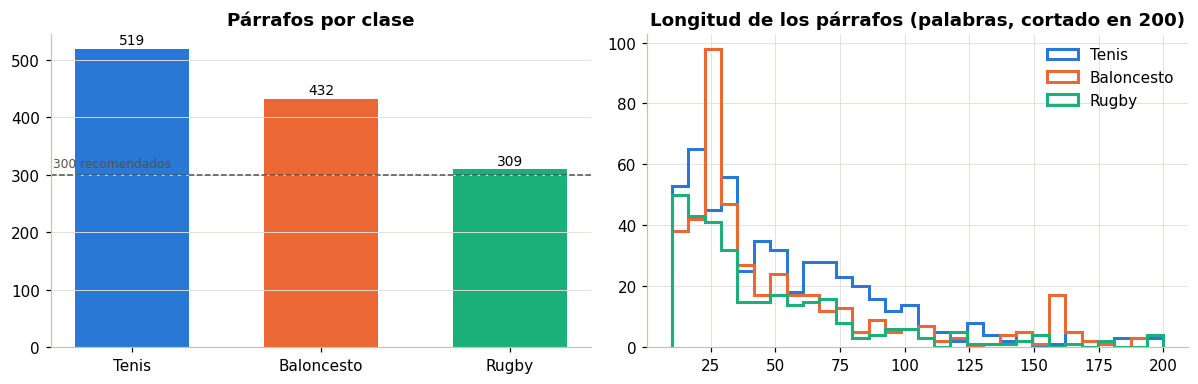

In [8]:
resumen = (df_dataset.assign(palabras=df_dataset["text"].str.split().str.len())
           .groupby("class")
           .agg(parrafos=("text", "size"), palabras_media=("palabras", "mean"),
                palabras_mediana=("palabras", "median"))
           .round(1).loc[list(CATEGORIAS)])
if df_meta is not None:
    resumen["articulos"] = df_meta.groupby("class")["titulo"].nunique()
    resumen["de_busqueda_%"] = (df_meta.groupby("class")["fuente"]
                                .apply(lambda s: 100 * (s == "busqueda").mean()).round(1))
display(resumen)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.bar([NOMBRES[c] for c in resumen.index], resumen["parrafos"],
       color=[COLORES[c] for c in resumen.index], width=0.6)
ax.axhline(300, color="#52514e", ls="--", lw=1)
ax.text(-0.42, 308, "300 recomendados", ha="left", va="bottom", fontsize=8, color="#52514e")
for i, v in enumerate(resumen["parrafos"]):
    ax.text(i, v + 8, str(v), ha="center", fontsize=9)
ax.set_title("Párrafos por clase")
ax.grid(axis="x", visible=False)

ax = axes[1]
longitudes = df_dataset["text"].str.split().str.len()
for c in CATEGORIAS:
    ax.hist(longitudes[df_dataset["class"] == c].clip(upper=200), bins=30,
            histtype="step", linewidth=2, color=COLORES[c], label=NOMBRES[c])
ax.set_title("Longitud de los párrafos (palabras, cortado en 200)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Observaciones:

* Las tres clases superan los 300 párrafos recomendados, aunque hay **desequilibrio** (tenis tiene más). Se tendrá en cuenta en la Fase 3 con partición estratificada, F1 *macro* (pondera igual cada clase) y `class_weight="balanced"`.
* En rugby gran parte del texto procede de muy pocos artículos (el artículo *Rugbeo* es muy largo). Esto puede hacer que el modelo aprenda el estilo de un artículo concreto; se evalúa explícitamente en la Fase 3 con validación agrupada por artículo.

### 2.9 El ruido de heredar la etiqueta del artículo

El enunciado avisa de que heredar la etiqueta introduce ruido: hay párrafos genéricos que no hablan de la temática (*"Ŝi naskiĝis en 1956 en Prago"*). Se mide de dos formas:

1. **Aquí (heurística):** porcentaje de párrafos que **no contienen ninguna palabra de la familia** de su clase (*tenis-*, *korbopilk-/basketbal-*, *rugbe-*). Es una cota aproximada: un párrafo puede ser de tenis sin decir "tenis" (*"gajnis la finalon de Wimbledon"*).
2. **En la Fase 3 (con el modelo):** párrafos que un clasificador entrenado sin verlos asigna con alta confianza a otra clase.

In [9]:
claves_re = {c: re.compile(cfg["clave"], re.IGNORECASE) for c, cfg in CATEGORIAS.items()}
con_clave = df_dataset.apply(lambda f: bool(claves_re[f["class"]].search(f["text"])), axis=1)
ruido = (pd.DataFrame({"class": df_dataset["class"], "sin_clave": ~con_clave})
         .groupby("class")["sin_clave"].agg(["sum", "mean"]).loc[list(CATEGORIAS)])
ruido.columns = ["párrafos sin palabra clave", "proporción"]
ruido["proporción"] = (100 * ruido["proporción"]).round(1).astype(str) + " %"
display(ruido)

print("Ejemplos de párrafos sin palabra clave (posible ruido):\n")
genericos = df_dataset[~con_clave & (df_dataset["text"].str.len() < 220)]
for _, f in genericos.groupby("class").head(2).iterrows():
    print(f"[{f['class']}] {f['text']}\n")

,párrafos sin palabra clave,proporción
class,,
teniso,168,32.4 %
korbopilkado,115,26.6 %
rugbeo,72,23.3 %


Ejemplos de párrafos sin palabra clave (posible ruido):

[teniso] Dumlude, la ludantoj ĉiam devas revenigi la pilkon per siaj rakedoj al kontraŭa kampo, provante samtempe malebligi tion al oponanto(j).

[teniso] La ludanto, kiu pilkofrapas la unua, povas fari same dum la daŭro de unu ludo. La rivalo pilkofrapos la unua en la sekva ludo kaj tiel plu laŭvice.

[korbopilkado] James Naismith establis aron de 13 bazaj reguloj por la ĵus naskita sporto:

[korbopilkado] La pilkon oni rajtas frapi ajndirekte, per unu aŭ du manoj (sed neniam per fermitaj pugno aŭ mano).

[rugbeo] En 1871, por ne konfuzi kun futbalo kaj ties "Football Association", kreiĝis la unua nacia organizado: la Rugby Football Union (RFU). En la sama jaro ankaŭ okazis la unua internacia matĉo inter Anglio kaj Skotlando.

[rugbeo] 1871 Oni fondis la Rugby Football Union, post kunveno de 25 kluboj ĉe restoracio de Pall Mall.



Más de un 25 % de los párrafos no nombra su deporte. Muchos son biográficos (fechas, nacionalidad, familia) y otros sí son del deporte aunque no lo nombren. Es el ruido que el enunciado pide reconocer. **No se eliminan**: hacerlo sesgaría el dataset hacia párrafos "fáciles" y el modelo después fallaría con textos reales, que no siempre nombran el deporte. Se cuantifica mejor en la Fase 3.

<a id="fase2"></a>
# 3. Fase 2 — Modelo de NLP para Esperanto

**Objetivo:** una librería de NLP **basada en reglas**, construida desde cero (sin spaCy, NLTK ni Stanza), con una API similar a spaCy:

```python
nlp = Esperanto()
doc = nlp("La tenisistoj ludis bonajn matĉojn.")
for token in doc:
    token.text, token.lemma_, token.pos_, token.morph, token.is_stop
```

### 3.1 Diseño

El Esperanto se presta a un analizador por reglas porque su morfología **no tiene excepciones**: una palabra es *raíz + afijos + terminación gramatical*, y la terminación indica la categoría y la flexión. El pipeline es:

```
texto ─► Normalizador ─► Tokenizador ─► Segmentador ─► Etiquetador (POS + morfología + lema + raíz) ─► Stop-words ─► Doc
```

| Componente | Reglas principales |
|---|---|
| **Normalizador** | Unicode NFC (diacríticos como un solo carácter), apóstrofos uniformes, sistema *x* opcional (`cx → ĉ`). |
| **Tokenizador** | Expresión regular con *longest-match*: URL → abreviatura (`k.t.p.`, `d-ro`) → número (`1.000`, `3-a`) → elisión (`l'`) → palabra (con guiones internos) → signo. |
| **Segmentador** | Corta tras `. ! ? …` solo si lo siguiente empieza frase (mayúscula, número, comillas). Las abreviaturas y los números decimales no cortan (resuelve los *ToDo* del segmentador del repositorio guía). |
| **Etiquetador** | Orden de decisión: signo/número → palabra cerrada del léxico → pronombre → correlativo → numeral → `esti` (AUX) → nombre propio → **terminación gramatical** (y participios). |
| **Lematizador** | Sustantivo → raíz + `-o`, adjetivo → `-a`, adverbio → `-e`, verbo → infinitivo `-i`. Además se calcula la **raíz** (*radiko*) quitando afijos productivos (`tenis-ist-o → tenis`). |
| **Stop-words** | Léxico del repositorio guía (`vortoj.json`) + pronombres + los 45 correlativos + formas de `esti` + numerales. |

Etiquetas POS: el conjunto universal (UPOS) que usa spaCy (`NOUN, ADJ, ADV, VERB, AUX, PRON, DET, ADP, CCONJ, SCONJ, NUM, PART, INTJ, PROPN, PUNCT, X`).

### 3.2 Recursos lingüísticos

Las reglas de la gramática (guía de la asignatura) se convierten en tablas de datos. El léxico de palabras funcionales se descarga del repositorio guía (`resources/esperanto/vortoj.json`); si GitHub no responde se usa una **copia embebida** idéntica, así la Fase 2 no depende de ninguna web.

In [10]:
# =============================================================================
# FASE 2 · Recursos lingüísticos
# =============================================================================
VORTOJ_URL = ("https://raw.githubusercontent.com/jparisu/nlp-esperantilo/"
              "main/resources/esperanto/vortoj.json")

# Copia embebida de vortoj.json (repositorio guía, licencia Apache-2.0):
# palabra -> (categoría gramatical, ¿es stop-word?)
VORTOJ_EMBEBIDO = {
    "adiaŭ": ("ĝentilaĵo", True), "ajn": ("partikulo", True), "al": ("prepozicio", True), "ankaŭ": ("adverbo", True),
    "ankoraŭ": ("adverbo", True), "anstataŭ": ("prepozicio", True), "antaŭ": ("prepozicio", True), "apenaŭ": ("adverbo", True),
    "apud": ("prepozicio", True), "aŭ": ("konjunkcio", True), "baldaŭ": ("adverbo", True), "bona": ("ĝentilaĵo", False),
    "bonvoli": ("ĝentilaĵo", True), "cent": ("nombro", True), "ci": ("pronomo", True), "da": ("prepozicio", True),
    "de": ("prepozicio", True), "dek": ("nombro", True), "des": ("partikulo", True), "do": ("konjunkcio", True),
    "doktoro": ("titolo", True), "du": ("nombro", True), "dum": ("prepozicio", True), "eble": ("adverbo", True),
    "ekster": ("prepozicio", True), "ekzemple": ("adverbo", True), "el": ("prepozicio", True), "en": ("prepozicio", True),
    "esti": ("verboformo", True), "eĉ": ("adverbo", True), "feliĉa": ("ĝentilaĵo", False), "for": ("adverbo", True),
    "fraŭlo": ("titolo", True), "ha": ("interjekcio", True), "havi": ("verboformo", True), "he": ("interjekcio", True),
    "hieraŭ": ("adverbo", True), "ho": ("interjekcio", True), "hodiaŭ": ("adverbo", True), "hu": ("interjekcio", True),
    "ili": ("pronomo", True), "inter": ("prepozicio", True), "ja": ("partikulo", True), "jam": ("adverbo", True),
    "je": ("prepozicio", True), "jen": ("partikulo", True), "jes": ("partikulo", True), "ju": ("partikulo", True),
    "kaj": ("konjunkcio", True), "ke": ("konjunkcio", True), "kontraŭ": ("prepozicio", True), "krom": ("prepozicio", True),
    "kun": ("prepozicio", True), "kvankam": ("konjunkcio", True), "kvar": ("nombro", True), "kvazaŭ": ("konjunkcio", True),
    "kvin": ("nombro", True), "la": ("artikolo", True), "laŭ": ("prepozicio", True), "li": ("pronomo", True),
    "male": ("adverbo", True), "malgraŭ": ("prepozicio", True), "mem": ("pronomo", True), "mi": ("pronomo", True),
    "mil": ("nombro", True), "miliardo": ("nombro", False), "miliono": ("nombro", False), "minus": ("nombro", True),
    "morgaŭ": ("adverbo", True), "naŭ": ("nombro", True), "ne": ("partikulo", True), "nek": ("konjunkcio", True),
    "nepre": ("adverbo", True), "ni": ("pronomo", True), "nu": ("interjekcio", True), "nul": ("nombro", True),
    "nun": ("adverbo", True), "nur": ("adverbo", True), "ok": ("nombro", True), "ol": ("konjunkcio", True),
    "oni": ("pronomo", True), "per": ("prepozicio", True), "plej": ("adverbo", True), "pli": ("adverbo", True),
    "plu": ("adverbo", True), "plus": ("nombro", True), "po": ("prepozicio", True), "por": ("prepozicio", True),
    "post": ("prepozicio", True), "povi": ("verboformo", True), "preskaŭ": ("adverbo", True), "preter": ("prepozicio", True),
    "pri": ("prepozicio", True), "pro": ("prepozicio", True), "se": ("konjunkcio", True), "sed": ("konjunkcio", True),
    "sen": ("prepozicio", True), "sep": ("nombro", True), "ses": ("nombro", True), "si": ("pronomo", True),
    "sinjoro": ("titolo", True), "sub": ("prepozicio", True), "super": ("prepozicio", True), "supre": ("adverbo", True),
    "sur": ("prepozicio", True), "tamen": ("konjunkcio", True), "tra": ("prepozicio", True), "trans": ("prepozicio", True),
    "tre": ("adverbo", True), "tri": ("nombro", True), "tro": ("adverbo", True), "tuj": ("adverbo", True),
    "tute": ("adverbo", True), "unu": ("nombro", True), "ve": ("interjekcio", True), "verŝajne": ("adverbo", True),
    "vi": ("pronomo", True), "ĉar": ("konjunkcio", True), "ĉe": ("prepozicio", True), "ĉi": ("partikulo", True),
    "ĉirkaŭ": ("prepozicio", True), "ĉu": ("partikulo", True), "ĝi": ("pronomo", True), "ĝis": ("prepozicio", True),
    "ĵus": ("adverbo", True), "ŝi": ("pronomo", True),
}


def cargar_lexicon(url=VORTOJ_URL, timeout=10):
    """Devuelve ({palabra: (categoria, es_stopword)}, origen)."""
    try:
        r = requests.get(url, timeout=timeout)
        r.raise_for_status()
        datos = r.json()
        lex = {w["vorto"]: (w["kategorio"], bool(w.get("ignorinda", False)))
               for w in datos["vortoj"]}
        return lex, "GitHub (vortoj.json)"
    except Exception as e:                       # sin red, 404, JSON inválido...
        return dict(VORTOJ_EMBEBIDO), f"copia embebida ({type(e).__name__})"


# Categoría del léxico -> etiqueta POS universal
CATEGORIA_A_POS = {
    "artikolo": "DET", "prepozicio": "ADP", "konjunkcio": "CCONJ",
    "pronomo": "PRON", "adverbo": "ADV", "partikulo": "PART",
    "verboformo": "VERB", "nombro": "NUM", "interjekcio": "INTJ",
    "ĝentilaĵo": "INTJ", "titolo": "NOUN",
}
SUBORDINANTES = {"ke", "se", "ĉar", "kvankam", "kvazaŭ", "ol"}   # -> SCONJ

# Pronombres personales (clase cerrada). El posesivo añade -a: mi -> mia.
PRONOMBRES = ["mi", "vi", "li", "ŝi", "ĝi", "ni", "ili", "oni", "si", "ci"]

# Correlativos: rejilla de 5 prefijos x 9 terminaciones = 45 palabras.
CORR_PREFIJOS = ["ki", "ti", "i", "ĉi", "neni"]
CORR_FINALES = {"o": "PRON", "u": "PRON", "a": "DET", "es": "DET", "e": "ADV",
                "am": "ADV", "al": "ADV", "el": "ADV", "om": "ADV"}

# Cardinales simples y compuestos por yuxtaposición: du, dek, dudek, tricent...
_UNIDADES = "unu|du|tri|kvar|kvin|ses|sep|ok|naŭ"
NUMERAL_RE = re.compile(
    rf"^(?:nul|(?:(?:{_UNIDADES})?(?:dek|cent|mil))+(?:{_UNIDADES})?|{_UNIDADES})$")

# Terminaciones gramaticales: (sufijo, POS, rasgos, final del lema).
# Ordenadas de más larga a más corta: regla longest-match.
TERMINACIONES = [
    ("ojn", "NOUN", {"Number": "Plur", "Case": "Acc"}, "o"),
    ("ajn", "ADJ", {"Number": "Plur", "Case": "Acc"}, "a"),
    ("oj", "NOUN", {"Number": "Plur", "Case": "Nom"}, "o"),
    ("on", "NOUN", {"Number": "Sing", "Case": "Acc"}, "o"),
    ("aj", "ADJ", {"Number": "Plur", "Case": "Nom"}, "a"),
    ("an", "ADJ", {"Number": "Sing", "Case": "Acc"}, "a"),
    ("en", "ADV", {"Case": "Acc"}, "e"),             # -en: dirección (hejmen)
    ("as", "VERB", {"VerbForm": "Fin", "Mood": "Ind", "Tense": "Pres"}, "i"),
    ("is", "VERB", {"VerbForm": "Fin", "Mood": "Ind", "Tense": "Past"}, "i"),
    ("os", "VERB", {"VerbForm": "Fin", "Mood": "Ind", "Tense": "Fut"}, "i"),
    ("us", "VERB", {"VerbForm": "Fin", "Mood": "Cnd"}, "i"),
    ("o", "NOUN", {"Number": "Sing", "Case": "Nom"}, "o"),
    ("a", "ADJ", {"Number": "Sing", "Case": "Nom"}, "a"),
    ("e", "ADV", {}, "e"),
    ("u", "VERB", {"VerbForm": "Fin", "Mood": "Jus"}, "i"),
    ("i", "VERB", {"VerbForm": "Inf"}, "i"),
]

# Participios: sufijo -> (tiempo, voz). ludanta, gajninta, nomita...
PARTICIPIOS = {"ant": ("Pres", "Act"), "int": ("Past", "Act"), "ont": ("Fut", "Act"),
               "at": ("Pres", "Pass"), "it": ("Past", "Pass"), "ot": ("Fut", "Pass")}
# Raíces que terminan como un participio pero no lo son (elefant-o, ŝtat-o...)
NO_PARTICIPIOS = {
    "elefant", "gigant", "diamant", "atlant", "briljant", "konstant", "galant",
    "important", "elegant", "variant", "konsonant", "amant", "kandidat", "soldat",
    "senat", "privat", "delikat", "kvadrat", "akurat", "rezultat", "ŝtat", "pilot",
    "spirit", "merit", "kredit", "limit", "horizont", "front", "pont", "mont",
    "format", "klimat", "aparat", "advokat", "favorit", "elit", "infinit",
    "dinamit", "magnat", "tomat", "salat", "deput", "agent", "talent",
}

# Afijos productivos para calcular la raíz (de forma conservadora).
SUFIJOS_DERIVATIVOS = ["estr", "ism", "ist", "ebl", "ind", "aĉ", "aĵ", "ad", "ar",
                       "ec", "eg", "ej", "em", "et", "ig", "iĝ", "il", "in", "ul",
                       "an", "ant", "int", "ont"]
PREFIJOS_DERIVATIVOS = ["mal"]

LETRAS_EO = set("abcĉdefgĝhĥijĵklmnoprsŝtuŭvz")   # sin q, w, x, y
VOCALES = set("aeiou")

# Sistema x: escritura sin diacríticos (cx = ĉ, gx = ĝ, ...)
SISTEMA_X = {"cx": "ĉ", "gx": "ĝ", "hx": "ĥ", "jx": "ĵ", "sx": "ŝ", "ux": "ŭ",
             "Cx": "Ĉ", "Gx": "Ĝ", "Hx": "Ĥ", "Jx": "Ĵ", "Sx": "Ŝ", "Ux": "Ŭ",
             "CX": "Ĉ", "GX": "Ĝ", "HX": "Ĥ", "JX": "Ĵ", "SX": "Ŝ", "UX": "Ŭ"}

# Abreviaturas frecuentes: su punto NO cierra la frase.
ABREVIATURAS = ["k.t.p", "k.a", "k.s", "t.e", "p.K", "a.K", "n-ro", "s-ro", "s-ino",
                "d-ro", "f-ino", "ktp", "ekz", "vd", "resp", "kp", "ks", "ĉ", "j",
                "jj", "km", "kg", "mm", "cm", "bv", "pĝ"]

# Palabras funcionales que faltan en vortoj.json y aparecen en el corpus
# (añadidas por el equipo tras revisar los tokens 'X' del apartado 3.9).
LEXICON_EXTRA = {"ambaŭ": ("pronomo", True), "almenaŭ": ("adverbo", True),
                 "malantaŭ": ("prepozicio", True), "ĉiam": ("adverbo", True)}

LEXICON, ORIGEN_LEXICON = cargar_lexicon()
for _w, _v in LEXICON_EXTRA.items():
    LEXICON.setdefault(_w, _v)
print(f"Léxico: {len(LEXICON)} palabras ({ORIGEN_LEXICON} + {len(LEXICON_EXTRA)} añadidas)")

Léxico: 130 palabras (GitHub (vortoj.json) + 4 añadidas)


### 3.3 Estructuras de datos: `Doc`, `Token`, `Span` y `MorphAnalysis`

Imitan los objetos de spaCy: un `Doc` es una secuencia de `Token`; cada token guarda el texto original (y el espacio que le sigue, para poder reconstruir el texto) y sus anotaciones. Las frases (`doc.sents`) son `Span`, trozos contiguos del `Doc`.

In [11]:
class MorphAnalysis:
    """Rasgos morfológicos al estilo spaCy: str() -> 'Case=Acc|Number=Plur'."""

    def __init__(self, rasgos=None):
        self._r = dict(rasgos or {})

    def get(self, clave, defecto=None):
        return self._r.get(clave, defecto)

    def to_dict(self):
        return dict(self._r)

    def __contains__(self, item):              # "Case=Acc" in token.morph
        return item in str(self).split("|")

    def __str__(self):
        return "|".join(f"{k}={v}" for k, v in sorted(self._r.items()))

    __repr__ = __str__


class Token:
    """Una unidad del texto (palabra, número, signo...) con sus anotaciones."""

    def __init__(self, doc, i, text, idx, whitespace, kind):
        self.doc = doc
        self.i = i                      # posición en el Doc
        self.text = text
        self.idx = idx                  # posición (en caracteres) en el texto
        self.whitespace_ = whitespace
        self.kind = kind                # tipo léxico asignado por el tokenizador
        self.lemma_ = text.lower()
        self.pos_ = "X"
        self.tag_ = ""                  # regla/terminación que decidió la etiqueta
        self.morph = MorphAnalysis()
        self.stem_ = text.lower()       # raíz sin afijos (radiko)
        self.is_stop = False
        self.is_sent_start = False

    @property
    def text_with_ws(self):
        return self.text + self.whitespace_

    @property
    def lower_(self):
        return self.text.lower()

    @property
    def is_punct(self):
        return self.kind == "punct"

    @property
    def is_alpha(self):
        return self.text.isalpha()

    @property
    def is_digit(self):
        return self.text.isdigit()

    @property
    def like_num(self):
        return self.kind == "num" or bool(NUMERAL_RE.match(self.lower_))

    @property
    def like_url(self):
        return self.kind == "url"

    @property
    def is_title(self):
        return self.text[:1].isupper()

    def __len__(self):
        return len(self.text)

    def __repr__(self):
        return self.text

    __str__ = __repr__


class Span:
    """Trozo contiguo de un Doc (p. ej. una frase de doc.sents)."""

    def __init__(self, doc, start, end):
        self.doc, self.start, self.end = doc, start, end

    def __iter__(self):
        return iter(self.doc.tokens[self.start:self.end])

    def __len__(self):
        return self.end - self.start

    def __getitem__(self, i):
        return self.doc.tokens[self.start:self.end][i]

    @property
    def text(self):
        return "".join(t.text_with_ws for t in self).strip()

    def __repr__(self):
        return self.text


class Doc:
    """Resultado de procesar un texto: secuencia de Token anotados."""

    def __init__(self, text):
        self.text = text
        self.tokens = []
        self._sents = []

    def __iter__(self):
        return iter(self.tokens)

    def __len__(self):
        return len(self.tokens)

    def __getitem__(self, i):
        if isinstance(i, slice):
            start, stop, _ = i.indices(len(self.tokens))
            return Span(self, start, stop)
        return self.tokens[i]

    @property
    def sents(self):
        return iter(self._sents)

    def __repr__(self):
        return self.text

    def to_pandas(self):
        """Tabla con todas las anotaciones (para inspeccionar el análisis)."""
        return pd.DataFrame([{"text": t.text, "lemma_": t.lemma_, "pos_": t.pos_,
                              "morph": str(t.morph), "stem_": t.stem_,
                              "is_stop": t.is_stop, "regla": t.tag_} for t in self.tokens])

### 3.4 Normalizador, tokenizador y segmentador de frases

In [12]:
class Normalizador:
    """Unicode NFC, apóstrofos uniformes y (opcional) sistema x -> diacríticos."""

    def __init__(self, sistema_x=False):
        self.sistema_x = sistema_x

    def __call__(self, texto):
        texto = unicodedata.normalize("NFC", texto)
        texto = texto.replace("’", "'").replace("‘", "'")
        if self.sistema_x:
            # Solo en palabras con cx/gx/.../ux, para no estropear "Alexander".
            def convertir(m):
                w = m.group(0)
                for k, v in SISTEMA_X.items():
                    w = w.replace(k, v)
                return w
            texto = re.sub(r"\b\w*[cghjsuCGHJSU][xX]\w*\b", convertir, texto)
        return texto


class Tokenizador:
    """Tokenizador por expresión regular con regla longest-match.

    El orden de las alternativas importa: primero los patrones más específicos
    (URL, abreviatura, número, elisión), después palabras y signos sueltos.
    """

    def __init__(self, abreviaturas=ABREVIATURAS):
        abbr = "|".join(re.escape(a) for a in sorted(abreviaturas, key=len, reverse=True))
        self.patron = re.compile(
            r"(?P<url>(?:https?://|www\.)\S*[^\s.,;:!?)\]])"
            rf"|(?P<abbr>(?<![^\W\d_])(?:{abbr})\.)"
            r"|(?P<num>\d+(?:[.,:]\d+)*(?:-(?:ajn|aj|an|a|e))?)"
            r"|(?P<elision>(?<![^\W\d_])l'(?=\s|$))"
            r"|(?P<word>[^\W\d_]+(?:[-'][^\W\d_]+)*)"
            r"|(?P<punct>[^\w\s])",
            re.IGNORECASE)

    def __call__(self, texto):
        doc = Doc(texto)
        for m in self.patron.finditer(texto):
            fin = m.end()
            ws = texto[fin] if fin < len(texto) and texto[fin].isspace() else ""
            doc.tokens.append(Token(doc, len(doc.tokens), m.group(0), m.start(), ws,
                                    m.lastgroup))
        return doc


class Segmentador:
    """Divide en frases: corta tras . ! ? … si lo siguiente empieza una frase."""

    FINALES = {".", "!", "?", "…"}
    CIERRES = {'"', "'", ")", "»", "”", "]"}
    APERTURAS = {'"', "«", "“", "("}

    def __call__(self, doc):
        inicio, n, i = 0, len(doc.tokens), 0
        while i < n:
            if doc.tokens[i].text in self.FINALES:
                j = i + 1
                while j < n and doc.tokens[j].text in self.CIERRES:
                    j += 1                    # comillas/paréntesis de cierre
                sig = doc.tokens[j] if j < n else None
                if (sig is None or sig.text[:1].isupper() or sig.kind == "num"
                        or sig.text in self.APERTURAS):
                    doc._sents.append(Span(doc, inicio, j))
                    inicio = i = j
                    continue
            i += 1
        if inicio < n:
            doc._sents.append(Span(doc, inicio, n))
        for s in doc._sents:
            doc.tokens[s.start].is_sent_start = True
        return doc


# Prueba rápida del tokenizador y del segmentador
_tok = Tokenizador()
_d = Segmentador()(_tok("D-ro Zamenhof naskiĝis la 15-an de decembro 1859. Li kreis "
                         "la lingvon en 1887, k.t.p. Vidu www.esperanto.net!"))
print([t.text for t in _d])
print([s.text for s in _d.sents])

['D-ro', 'Zamenhof', 'naskiĝis', 'la', '15-an', 'de', 'decembro', '1859', '.', 'Li', 'kreis', 'la', 'lingvon', 'en', '1887', ',', 'k.t.p.', 'Vidu', 'www.esperanto.net', '!']
['D-ro Zamenhof naskiĝis la 15-an de decembro 1859.', 'Li kreis la lingvon en 1887, k.t.p. Vidu www.esperanto.net!']


### 3.5 Etiquetador morfológico, lematizador y raíces

El corazón del modelo. Para cada token se aplica la **primera regla que encaja**, de la más específica a la más general. Casos especiales que resuelve:

* **Nombres propios.** Mayúscula fuera de inicio de frase, o letras que no existen en Esperanto (`w`, `x`, `y`, `q`): *Federer, Wimbledon* → `PROPN`. Si el nombre está esperantizado se lematiza igual: *Francion* → *Francio*.
* **Participios** (no los cubre la guía): *ludanto* (el que juega) → `NOUN`, raíz *lud*; *nomita* (nombrado) → `VERB` con `VerbForm=Part|Tense=Past|Voice=Pass` y lema *nomi*. Una lista de excepciones evita falsos participios (*elefanto, ŝtato, kandidato*).
* **Raíz (`stem_`)**: además del lema se quitan afijos productivos, de modo que *tenisisto, tenisa, tenisejo* comparten la raíz `tenis`. Es útil para clasificar porque junta toda la familia de palabras.

In [13]:
class Etiquetador:
    """POS-tagging + análisis morfológico + lematización + raíz, por reglas."""

    def __init__(self, lexicon):
        self.cerradas = {w: c for w, (c, stop) in lexicon.items() if stop and c != "verboformo"}
        # Formas de los pronombres: mi, min, mia, miaj, mian, miajn
        self.pronombres = {}
        for p in PRONOMBRES:
            self.pronombres[p] = (p, "PRON", {"PronType": "Prs", "Case": "Nom"})
            self.pronombres[p + "n"] = (p, "PRON", {"PronType": "Prs", "Case": "Acc"})
            for suf, feats in [("a", {"Number": "Sing", "Case": "Nom"}),
                               ("aj", {"Number": "Plur", "Case": "Nom"}),
                               ("an", {"Number": "Sing", "Case": "Acc"}),
                               ("ajn", {"Number": "Plur", "Case": "Acc"})]:
                self.pronombres[p + suf] = (p + "a", "DET", {"Poss": "Yes", **feats})
        # Correlativos generados desde la rejilla, con su flexión permitida
        self.correlativos = {}
        for pre in CORR_PREFIJOS:
            for fin, pos in CORR_FINALES.items():
                base = pre + fin
                formas = {base: {}}
                if fin in ("u", "a"):           # tiuj, tiun, tiujn
                    formas.update({base + "j": {"Number": "Plur"}, base + "n": {"Case": "Acc"},
                                   base + "jn": {"Number": "Plur", "Case": "Acc"}})
                elif fin in ("o", "e"):         # tion, tien (nunca *tioj)
                    formas[base + "n"] = {"Case": "Acc"}
                for forma, feats in formas.items():
                    self.correlativos[forma] = (base, pos, {"PronType": "Corr", **feats})

    @staticmethod
    def _raiz_valida(raiz):
        """Una raíz del Esperanto: >=2 letras del alfabeto eo y alguna vocal."""
        return (len(raiz) >= 2 and set(raiz) <= LETRAS_EO
                and any(c in VOCALES for c in raiz))

    def analizar_morfologia(self, w):
        """Análisis por terminación. Devuelve (lema, pos, rasgos, regla) o None."""
        for suf, pos, rasgos, fin_lema in TERMINACIONES:
            if not w.endswith(suf):
                continue
            raiz = w[:-len(suf)]
            if not self._raiz_valida(raiz):
                continue
            rasgos = dict(rasgos)
            if pos in ("ADJ", "ADV", "NOUN"):          # ¿participio?
                for p, (tiempo, voz) in PARTICIPIOS.items():
                    if not raiz.endswith(p) or raiz in NO_PARTICIPIOS:
                        continue
                    verbo = raiz[:-len(p)]
                    if len(verbo) < 3 or not self._raiz_valida(verbo):
                        continue
                    if pos == "NOUN" and voz == "Pass":  # -ato/-ito: casi siempre raíz simple
                        continue
                    rasgos.update({"VerbForm": "Part", "Tense": tiempo, "Voice": voz})
                    if pos == "NOUN":                    # ludanto: el que juega
                        return raiz + "o", "NOUN", rasgos, f"-{p}{suf}"
                    return verbo + "i", "VERB", rasgos, f"-{p}{suf}"
            if pos == "ADJ" and NUMERAL_RE.match(raiz):
                rasgos["NumType"] = "Ord"                # unua, dudeka
            return raiz + fin_lema, pos, rasgos, f"-{suf}"
        return None

    @staticmethod
    def calcular_raiz(lema, pos):
        """Raíz (radiko): lema sin terminación ni afijos productivos."""
        if pos not in ("NOUN", "ADJ", "ADV", "VERB") or len(lema) < 3:
            return lema
        raiz, cambiado = lema[:-1], True
        while cambiado:                       # tenisist -> tenis
            cambiado = False
            for suf in SUFIJOS_DERIVATIVOS:
                if raiz.endswith(suf) and len(raiz) - len(suf) >= 3:
                    raiz, cambiado = raiz[:-len(suf)], True
                    break
        for pre in PREFIJOS_DERIVATIVOS:      # malvenk -> venk
            if raiz.startswith(pre) and len(raiz) - len(pre) >= 3:
                raiz = raiz[len(pre):]
        return raiz

    def etiquetar_token(self, t):
        w = t.lower_
        # 1. Tipo léxico decidido por el tokenizador
        if t.kind == "punct":
            t.pos_, t.lemma_, t.tag_ = "PUNCT", t.text, "punct"
            return
        if t.kind in ("url", "abbr"):
            t.pos_, t.tag_ = "X", t.kind
            return
        if t.kind == "num":
            t.pos_, t.tag_ = "NUM", "num"
            t.morph = MorphAnalysis({"NumType": "Ord" if "-" in w else "Card"})
            return
        if t.kind == "elision":                         # l' = la
            t.pos_, t.lemma_, t.tag_ = "DET", "la", "elision"
            t.morph = MorphAnalysis({"Definite": "Def", "PronType": "Art"})
            return
        # 2. Palabras cerradas del léxico (artículo, preposiciones, ...)
        if w in self.cerradas:
            cat = self.cerradas[w]
            pos = "SCONJ" if (cat == "konjunkcio" and w in SUBORDINANTES) \
                else CATEGORIA_A_POS.get(cat, "X")
            t.pos_, t.lemma_, t.tag_ = pos, w, f"lex:{cat}"
            if w == "la":
                t.morph = MorphAnalysis({"Definite": "Def", "PronType": "Art"})
            return
        # 3-4. Pronombres y correlativos
        for tabla, regla in ((self.pronombres, "pron"), (self.correlativos, "corr")):
            if w in tabla:
                t.lemma_, t.pos_, rasgos = tabla[w]
                t.morph, t.tag_ = MorphAnalysis(rasgos), regla
                return
        # 5. Numerales escritos con letras
        if NUMERAL_RE.match(w):
            t.pos_, t.lemma_, t.tag_ = "NUM", w, "numeral"
            t.morph = MorphAnalysis({"NumType": "Card"})
            return
        analisis = self.analizar_morfologia(w)
        if analisis and analisis[0] == "esti" and analisis[1] == "VERB":   # copulativo
            t.lemma_, t.pos_, rasgos, t.tag_ = "esti", "AUX", analisis[2], analisis[3]
            t.morph = MorphAnalysis(rasgos)
            return
        # 6. Nombres propios
        extranjera = not set(w) <= LETRAS_EO
        if t.is_title and (not t.is_sent_start or analisis is None or extranjera):
            t.pos_, t.tag_ = "PROPN", "propn"
            if analisis and not extranjera and analisis[1] == "NOUN":
                t.lemma_ = analisis[0][0].upper() + analisis[0][1:]   # Francion -> Francio
                t.morph = MorphAnalysis(analisis[2])
            else:
                t.lemma_ = t.text                                       # Federer
            return
        # 7. Terminación gramatical
        if analisis is None or extranjera:
            t.pos_, t.tag_ = "X", "desconocida"      # palabra extranjera o sin terminación eo
            return
        t.lemma_, t.pos_, rasgos, t.tag_ = analisis
        t.morph = MorphAnalysis(rasgos)

    def __call__(self, doc):
        for t in doc:
            self.etiquetar_token(t)
            t.stem_ = self.calcular_raiz(t.lemma_.lower(), t.pos_)
        return doc

### 3.6 Gestión de *stop-words* y clase principal `Esperanto`

La lista de *stop-words* es **modificable** (`nlp.stop_words.add(...)`), como en spaCy. `Esperanto` monta el pipeline y expone `nlp(texto)`, `nlp.pipe(textos)`, `nlp.tokenizer(texto)`, `nlp.pipe_names` y `nlp.get_pipe(nombre)`.

In [14]:
class GestorStopwords:
    """Marca token.is_stop. Lista = léxico (ignorinda) + pronombres +
    correlativos + 'esti' + numerales + extras opcionales."""

    def __init__(self, lexicon, extra=()):
        self.stop_words = {w for w, (c, stop) in lexicon.items() if stop}
        self.stop_words.update(PRONOMBRES)
        self.stop_words.update(p + "a" for p in PRONOMBRES)
        self.stop_words.update(pre + fin for pre in CORR_PREFIJOS for fin in CORR_FINALES)
        self.stop_words.update(extra)

    def __call__(self, doc):
        for t in doc:
            t.is_stop = (t.lower_ in self.stop_words
                         or t.lemma_.lower() in self.stop_words
                         or t.pos_ in ("AUX", "NUM")
                         or t.tag_ in ("pron", "corr"))
        return doc


class Esperanto:
    """Modelo de NLP para Esperanto con API similar a spaCy.

    >>> nlp = Esperanto()
    >>> doc = nlp("La tenisistoj ludis bonajn matĉojn.")
    >>> [(t.text, t.lemma_, t.pos_) for t in doc]
    """

    lang = "eo"

    def __init__(self, lexicon=None, sistema_x=False, stop_extra=()):
        lexicon = LEXICON if lexicon is None else lexicon
        self.normalizer = Normalizador(sistema_x)
        self._tokenizer = Tokenizador()
        self.pipeline = [("sentencizer", Segmentador()),
                         ("tagger", Etiquetador(lexicon)),
                         ("stopwords", GestorStopwords(lexicon, stop_extra))]

    @property
    def pipe_names(self):
        return ["normalizer", "tokenizer"] + [nombre for nombre, _ in self.pipeline]

    def get_pipe(self, nombre):
        return dict(self.pipeline)[nombre]

    @property
    def stop_words(self):
        return self.get_pipe("stopwords").stop_words

    def tokenizer(self, texto):
        """Solo normaliza y tokeniza (como nlp.tokenizer de spaCy)."""
        return self._tokenizer(self.normalizer(texto))

    def __call__(self, texto):
        doc = self.tokenizer(texto)
        for _, componente in self.pipeline:
            doc = componente(doc)
        return doc

    def pipe(self, textos):
        for texto in textos:
            yield self(texto)


nlp = Esperanto()
print("Pipeline:", nlp.pipe_names, "| stop-words:", len(nlp.stop_words))

Pipeline: ['normalizer', 'tokenizer', 'sentencizer', 'tagger', 'stopwords'] | stop-words: 180


### 3.7 Demostración

Las dos frases de ejemplo de la guía de gramática y una frase típica del corpus.

In [15]:
for frase in ["La juna instruistino legas interesan libron.",
              "Ĉiuj miaj amikoj legas tiujn librojn.",
              "Roger Federer, svisa tenisisto, gajnis la turniron de Wimbledon en 2003; "
              "la ludantoj estis nomitaj de la trejnisto."]:
    doc = nlp(frase)
    print("▶", frase)
    display(doc.to_pandas())

▶ La juna instruistino legas interesan libron.


,text,lemma_,pos_,morph,stem_,is_stop,regla
0,La,la,DET,Definite=Def|PronType=Art,la,True,lex:artikolo
1,juna,juna,ADJ,Case=Nom|Number=Sing,jun,False,-a
2,instruistino,instruistino,NOUN,Case=Nom|Number=Sing,instru,False,-o
3,legas,legi,VERB,Mood=Ind|Tense=Pres|VerbForm=Fin,leg,False,-as
4,interesan,interesa,ADJ,Case=Acc|Number=Sing,interes,False,-an
5,libron,libro,NOUN,Case=Acc|Number=Sing,libr,False,-on
6,.,.,PUNCT,,.,False,punct


▶ Ĉiuj miaj amikoj legas tiujn librojn.


,text,lemma_,pos_,morph,stem_,is_stop,regla
0,Ĉiuj,ĉiu,PRON,Number=Plur|PronType=Corr,ĉiu,True,corr
1,miaj,mia,DET,Case=Nom|Number=Plur|Poss=Yes,mia,True,pron
2,amikoj,amiko,NOUN,Case=Nom|Number=Plur,amik,False,-oj
3,legas,legi,VERB,Mood=Ind|Tense=Pres|VerbForm=Fin,leg,False,-as
4,tiujn,tiu,PRON,Case=Acc|Number=Plur|PronType=Corr,tiu,True,corr
5,librojn,libro,NOUN,Case=Acc|Number=Plur,libr,False,-ojn
6,.,.,PUNCT,,.,False,punct


▶ Roger Federer, svisa tenisisto, gajnis la turniron de Wimbledon en 2003; la ludantoj estis nomitaj de la trejnisto.


,text,lemma_,pos_,morph,stem_,is_stop,regla
0,Roger,Roger,PROPN,,roger,False,propn
1,Federer,Federer,PROPN,,federer,False,propn
2,",",",",PUNCT,,",",False,punct
3,svisa,svisa,ADJ,Case=Nom|Number=Sing,svis,False,-a
4,tenisisto,tenisisto,NOUN,Case=Nom|Number=Sing,tenis,False,-o
5,",",",",PUNCT,,",",False,punct
6,gajnis,gajni,VERB,Mood=Ind|Tense=Past|VerbForm=Fin,gajn,False,-is
7,la,la,DET,Definite=Def|PronType=Art,la,True,lex:artikolo
8,turniron,turniro,NOUN,Case=Acc|Number=Sing,turnir,False,-on
9,de,de,ADP,,de,True,lex:prepozicio


In [16]:
doc = nlp("La korbopilkistoj de NBA ludis bone. Ĉu la rugbea teamo de Francio venkos?")
print("Frases:", [s.text for s in doc.sents])
t = doc[1]
print(f"\nAPI tipo spaCy sobre el token '{t}': lemma_={t.lemma_!r}, pos_={t.pos_!r}, "
      f"morph={t.morph}, Number={t.morph.get('Number')}, stem_={t.stem_!r}, "
      f"is_stop={t.is_stop}, is_sent_start={t.is_sent_start}")
print("Tokens de contenido:", [t.lemma_ for t in doc if not t.is_stop and not t.is_punct])

Frases: ['La korbopilkistoj de NBA ludis bone.', 'Ĉu la rugbea teamo de Francio venkos?']

API tipo spaCy sobre el token 'korbopilkistoj': lemma_='korbopilkisto', pos_='NOUN', morph=Case=Nom|Number=Plur, Number=Plur, stem_='korbopilk', is_stop=False, is_sent_start=False
Tokens de contenido: ['korbopilkisto', 'NBA', 'ludi', 'bone', 'rugbea', 'teamo', 'Francio', 'venki']


### 3.8 Pruebas del modelo

Dos tipos de prueba para demostrar que funciona:

1. **Pruebas unitarias** (`assert`) de cada regla: si alguien rompe una regla, el cuaderno falla aquí.
2. **Evaluación contra un pequeño *gold standard***: frases etiquetadas a mano (POS y lema correctos) para medir la precisión del etiquetador y del lematizador.

In [17]:
def analisis(palabra_o_frase, i=0):
    t = nlp(palabra_o_frase)[i]
    return t.lemma_, t.pos_, str(t.morph)

# --- Morfología regular ---
assert analisis("librojn") == ("libro", "NOUN", "Case=Acc|Number=Plur")
assert analisis("bonan") == ("bona", "ADJ", "Case=Acc|Number=Sing")
assert analisis("rapide") == ("rapide", "ADV", "")
assert analisis("kantis")[:2] == ("kanti", "VERB") and "Tense=Past" in analisis("kantis")[2]
assert analisis("kantus")[2] == "Mood=Cnd|VerbForm=Fin"
assert analisis("estas")[:2] == ("esti", "AUX")
# --- Participios y raíces ---
assert analisis("ludantoj")[:2] == ("ludanto", "NOUN")
assert analisis("nomita")[:2] == ("nomi", "VERB")
assert analisis("elefanto")[:2] == ("elefanto", "NOUN")             # excepción
assert nlp("tenisisto")[0].stem_ == nlp("tenisejo")[0].stem_ == "tenis"
assert nlp("korbopilkistoj")[0].stem_ == "korbopilk"
# --- Palabras cerradas, pronombres y correlativos ---
assert analisis("la")[1] == "DET" and analisis("kun")[1] == "ADP"
assert analisis("ke")[1] == "SCONJ" and analisis("kaj")[1] == "CCONJ"
assert analisis("miajn")[:2] == ("mia", "DET")
assert analisis("tiujn")[:2] == ("tiu", "PRON") and analisis("kiam")[1] == "ADV"
assert analisis("dudek")[1] == "NUM" and analisis("unua")[2] == "Case=Nom|NumType=Ord|Number=Sing"
# --- Nombres propios, tokenización y frases ---
assert analisis("Mi vidis Federer", 2)[1] == "PROPN"
assert analisis("Ni vizitis Francion", 2)[:2] == ("Francio", "PROPN")
assert [t.text for t in nlp("l' homo")] == ["l'", "homo"]
assert [t.text for t in nlp("en 1.000,5 eŭroj")][1] == "1.000,5"
assert len(list(nlp("D-ro Zamenhof venis. Li parolis.").sents)) == 2
assert len(list(nlp("Li gajnis 6.3 poentojn kaj k.t.p. ankaŭ.").sents)) == 1
# --- Stop-words ---
d = nlp("La tenisisto estas tre bona kaj li ludas kun ŝi.")
assert [t.text for t in d if not t.is_stop and not t.is_punct] == ["tenisisto", "bona", "ludas"]
# --- Sistema x ---
assert Esperanto(sistema_x=True)("ŝi mangxas cxokoladon")[1].lemma_ == "manĝi"
print("✔ Todas las pruebas unitarias del modelo NLP pasan")

✔ Todas las pruebas unitarias del modelo NLP pasan


In [18]:
# Gold standard: frases anotadas a mano (palabra|lema|POS), del ámbito deportivo
GOLD = """
La|la|DET tenisistino|tenisistino|NOUN gajnis|gajni|VERB sian|sia|DET unuan|unua|ADJ turniron|turniro|NOUN en|en|ADP Parizo|Parizo|PROPN .|.|PUNCT
Ŝi|ŝi|PRON estas|esti|AUX unu|unu|NUM el|el|ADP la|la|DET plej|plej|ADV sukcesaj|sukcesa|ADJ ludantinoj|ludantino|NOUN de|de|ADP sia|sia|DET generacio|generacio|NOUN .|.|PUNCT
La|la|DET korbopilka|korbopilka|ADJ teamo|teamo|NOUN venkis|venki|VERB kontraŭ|kontraŭ|ADP Bostono|Bostono|PROPN kun|kun|ADP granda|granda|ADJ diferenco|diferenco|NOUN .|.|PUNCT
Li|li|PRON ludis|ludi|VERB dum|dum|ADP dek|dek|NUM sezonoj|sezono|NOUN en|en|ADP NBA|NBA|PROPN kaj|kaj|CCONJ poste|poste|ADV iĝis|iĝi|VERB trejnisto|trejnisto|NOUN .|.|PUNCT
Rugbeo|rugbeo|NOUN estas|esti|AUX teama|teama|ADJ sporto|sporto|NOUN ,|,|PUNCT kiun|kiu|PRON oni|oni|PRON ludas|ludi|VERB per|per|ADP ovoforma|ovoforma|ADJ pilko|pilko|NOUN .|.|PUNCT
Kiam|kiam|ADV la|la|DET ludantoj|ludanto|NOUN eniris|eniri|VERB la|la|DET stadionon|stadiono|NOUN ,|,|PUNCT ĉiuj|ĉiu|PRON spektantoj|spektanto|NOUN kriis|krii|VERB .|.|PUNCT
La|la|DET turniro|turniro|NOUN estis|esti|AUX fondita|fondi|VERB en|en|ADP 1877|1877|NUM kaj|kaj|CCONJ okazas|okazi|VERB ĉiujare|ĉiujare|ADV en|en|ADP Londono|Londono|PROPN .|.|PUNCT
Francio|Francio|PROPN venkis|venki|VERB Anglion|Anglio|PROPN en|en|ADP la|la|DET finalo|finalo|NOUN de|de|ADP US|US|PROPN Open|Open|PROPN .|.|PUNCT
Ŝi|ŝi|PRON estis|esti|AUX konata|koni|VERB kiel|kiel|ADV la|la|DET plej|plej|ADV rapida|rapida|ADJ servanto|servanto|NOUN de|de|ADP la|la|DET teamo|teamo|NOUN .|.|PUNCT
Ĉu|ĉu|PART vi|vi|PRON scias|scii|VERB ke|ke|SCONJ la|la|DET franca|franca|ADJ teamo|teamo|NOUN malvenkis|malvenki|VERB hieraŭ|hieraŭ|ADV ?|?|PUNCT
"""
gold_ok_pos = gold_ok_lema = total = 0
errores = []
for linea in GOLD.strip().split("\n"):
    anot = [x.split("|") for x in linea.split()]
    doc = nlp(" ".join(a[0] for a in anot).replace(" .", ".").replace(" ,", ",").replace(" ?", "?"))
    assert len(doc) == len(anot), (linea, [t.text for t in doc])
    for t, (w, lema, pos) in zip(doc, anot):
        total += 1
        gold_ok_pos += t.pos_ == pos
        gold_ok_lema += t.lemma_ == lema
        if t.pos_ != pos or t.lemma_ != lema:
            errores.append((w, f"{t.lemma_}/{t.pos_}", f"{lema}/{pos}"))
print(f"Tokens evaluados: {total}")
print(f"Precisión POS:   {gold_ok_pos / total:.1%}")
print(f"Precisión lema:  {gold_ok_lema / total:.1%}")
print("Errores (palabra, predicho, correcto):", errores)

Tokens evaluados: 110
Precisión POS:   99.1%
Precisión lema:  99.1%
Errores (palabra, predicho, correcto): [('Francio', 'francio/NOUN', 'Francio/PROPN')]


### 3.9 El modelo aplicado al corpus

Se procesa todo el dataset una sola vez (los `Doc` se reutilizan en la Fase 3). Dos comprobaciones útiles:

* **Cobertura:** qué parte de los tokens no se puede analizar (`X`). Son sobre todo palabras extranjeras (*Open, Grand, Lakers*) y siglas.
* **Reducción del vocabulario:** cuántas formas distintas se agrupan al lematizar y al quedarse con la raíz. Es justo lo que ayuda al clasificador: *tenisisto, tenisistino, tenisistoj, tenisistojn* pasan a ser un mismo término.

1260 párrafos, 77,365 tokens procesados en 2.8 s


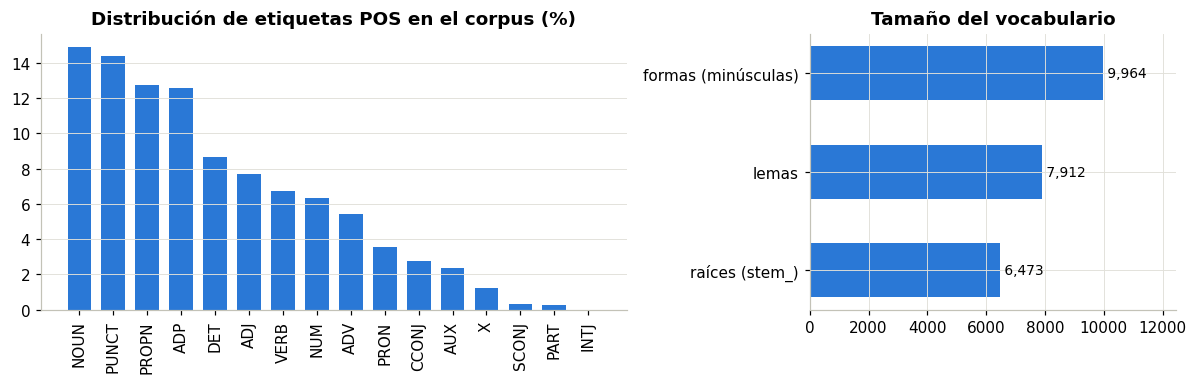

Tokens 'X' (no analizables): 1.3 % | más frecuentes: ['m', 'a', 'of', 'l', 'nˈaʃənə', 'bˈaskɪtbɔːl', 'ɐsə', 'ʊsɪˈe', 'ɪʃən', 'ɛn', 'biː', 'ˈe']


In [19]:
t0 = time.perf_counter()
DOCS = list(nlp.pipe(df_dataset["text"]))
T_NLP = time.perf_counter() - t0
n_tokens = sum(len(d) for d in DOCS)
print(f"{len(DOCS)} párrafos, {n_tokens:,} tokens procesados en {T_NLP:.1f} s")

pos_freq = pd.Series([t.pos_ for d in DOCS for t in d]).value_counts(normalize=True) * 100
palabras = [t for d in DOCS for t in d if t.is_alpha]
vocab = pd.Series({
    "formas (minúsculas)": len({t.lower_ for t in palabras}),
    "lemas": len({t.lemma_.lower() for t in palabras}),
    "raíces (stem_)": len({t.stem_ for t in palabras}),
})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].bar(pos_freq.index, pos_freq.values, color="#2a78d6", width=0.7)
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_title("Distribución de etiquetas POS en el corpus (%)")
axes[0].grid(axis="x", visible=False)
axes[1].barh(vocab.index, vocab.values, color="#2a78d6", height=0.55)
for i, v in enumerate(vocab):
    axes[1].text(v, i, f" {v:,}", va="center", fontsize=9)
axes[1].set_title("Tamaño del vocabulario")
axes[1].invert_yaxis()
axes[1].set_xlim(0, vocab.max() * 1.25)
plt.tight_layout()
plt.show()

desconocidas = Counter(t.text for d in DOCS for t in d if t.pos_ == "X" and t.is_alpha)
print(f"Tokens 'X' (no analizables): {pos_freq.get('X', 0):.1f} % | más frecuentes:",
      [w for w, _ in desconocidas.most_common(12)])

**Limitaciones conocidas del modelo (y por qué son aceptables):**

* Las palabras con mayúscula **a principio de frase** que tienen terminación del Esperanto se tratan como palabras comunes (*Francion* → `NOUN`), porque por la forma no se pueden distinguir. Para clasificar no importa: el lema es el mismo.
* La raíz se calcula de forma **conservadora** (solo sufijos productivos y quedando al menos 3 letras), así que algunas palabras se descomponen de más (*maŝino → maŝ*). Como el error es **consistente** (siempre igual), no perjudica a la vectorización.
* No hay análisis sintáctico (fuera del alcance del curso, como indican las transparencias).

<a id="fase3"></a>
# 4. Fase 3 — Clasificación

**Objetivo:** representar el corpus en forma tabular con el modelo NLP, entrenar un clasificador y evaluarlo con la metodología estándar.

### 4.1 Preprocesamiento con el modelo NLP

Siguiendo la metodología del tema 2.3 (*tokenización → filtrado → normalización → representación*), cada párrafo se convierte en una lista de términos. Se comparan tres representaciones para **medir lo que aporta el modelo NLP**:

| Representación | Términos | Usa la Fase 2 |
|---|---|---|
| `forma` | palabras en minúsculas tal cual (línea base, sin NLP) | solo tokenizador |
| `lema` | lemas de palabras de contenido (sin *stop-words*, signos ni números) | todo el pipeline |
| `raiz` | raíces (`stem_`) de palabras de contenido | todo el pipeline + afijos |

In [20]:
POS_CONTENIDO = {"NOUN", "ADJ", "VERB", "ADV", "PROPN"}


def terminos(doc, modo="lema"):
    """Convierte un Doc en la lista de términos que verá el clasificador."""
    if modo == "forma":
        return [t.lower_ for t in doc if t.is_alpha]
    utiles = [t for t in doc if not t.is_stop and t.pos_ in POS_CONTENIDO and len(t.text) > 1]
    if modo == "lema":
        return [t.lemma_.lower() for t in utiles]
    if modo == "raiz":
        return [t.stem_ for t in utiles]
    raise ValueError(modo)


REPRESENTACIONES = {m: [terminos(d, m) for d in DOCS] for m in ("forma", "lema", "raiz")}
y = df_dataset["class"].to_numpy()
print("Ejemplo:", df_dataset["text"].iloc[0][:120], "...")
for m, X in REPRESENTACIONES.items():
    print(f"  {m:6s} -> {X[0][:12]}")

Ejemplo: Teniso estas rakedsporto, kutime ludata de du homoj, sed ankaŭ foje de kvar homoj (para teniso). Specifa para ludo estas ...
  forma  -> ['teniso', 'estas', 'rakedsporto', 'kutime', 'ludata', 'de', 'du', 'homoj', 'sed', 'ankaŭ', 'foje', 'de']
  lema   -> ['teniso', 'rakedsporto', 'kutime', 'ludi', 'homo', 'foje', 'homo', 'para', 'teniso', 'specifa', 'para', 'ludo']
  raiz   -> ['tenis', 'rakedsport', 'kutim', 'lud', 'hom', 'foj', 'hom', 'par', 'tenis', 'specif', 'par', 'lud']


### 4.2 Vectorización

Se implementan **desde cero** las dos técnicas del tema 2.4 como transformadores compatibles con scikit-learn (`fit` / `transform`), para poder meterlas en un `Pipeline` y validarlas sin fugas de información:

* **`BolsaDePalabras` (BoW):** vector de palabras elegido por frecuencia (las que aparecen en al menos `min_df` documentos, opcionalmente las `max_features` más frecuentes) y valor = **frecuencia relativa** del término en el texto (normalizado, para que la longitud no afecte).
* **`TfIdfClases` (TF-IDF del profesor):** la variante vista en clase, en la que el IDF se calcula sobre **clases**, no sobre documentos:

$$TF(t,d)=\frac{f(t,d)}{\sum_{t'\in d} f(t',d)} \qquad IDF(t,C)=1-\log_{|C|}\big(\max(1,\ |\{c_i\in C : t\in c_i\}|)\big)$$

  Con 3 clases, un término que solo aparece en una clase tiene IDF = 1; en dos, 1 − log₃2 ≈ 0,37; y en las tres, 0 (no discrimina). Como el IDF usa las etiquetas, **se calcula solo con los datos de entrenamiento** de cada partición (si no, habría fuga de información). Se añade normalización L2 opcional, como sugieren las transparencias.

También se compara con el **TF-IDF clásico** de scikit-learn (IDF sobre documentos).

In [21]:
def identidad(x):
    """Analizador para TfidfVectorizer: los textos ya vienen tokenizados."""
    return x


class BolsaDePalabras(BaseEstimator, TransformerMixin):
    """Bag of Words: frecuencia relativa de cada término del vector de palabras."""

    def __init__(self, min_df=2, max_features=None):
        self.min_df = min_df
        self.max_features = max_features

    def fit(self, X, y=None):
        df = Counter(t for doc in X for t in set(doc))          # nº de documentos
        tf = Counter(t for doc in X for t in doc)                # frecuencia total
        candidatos = [t for t, n in df.items() if n >= self.min_df]
        candidatos.sort(key=lambda t: (-tf[t], t))
        if self.max_features:
            candidatos = candidatos[:self.max_features]
        self.vocabulario_ = {t: j for j, t in enumerate(sorted(candidatos))}
        return self

    def _tf(self, X):
        filas, cols, vals = [], [], []
        for i, doc in enumerate(X):
            n = len(doc) or 1
            for t, c in Counter(doc).items():
                j = self.vocabulario_.get(t)
                if j is not None:
                    filas.append(i); cols.append(j); vals.append(c / n)
        return sp.csr_matrix((vals, (filas, cols)), shape=(len(X), len(self.vocabulario_)))

    def transform(self, X):
        return self._tf(X)

    def get_feature_names_out(self, input_features=None):
        return np.array(sorted(self.vocabulario_, key=self.vocabulario_.get))


class TfIdfClases(BolsaDePalabras):
    """TF-IDF con IDF calculado sobre clases (fórmula de las transparencias)."""

    def __init__(self, min_df=2, max_features=None, normalizar=True):
        super().__init__(min_df=min_df, max_features=max_features)
        self.normalizar = normalizar

    def fit(self, X, y):
        super().fit(X)
        y = np.asarray(y)
        self.clases_ = np.unique(y)
        presente = np.zeros((len(self.clases_), len(self.vocabulario_)), dtype=bool)
        for doc, c in zip(X, y):
            k = np.searchsorted(self.clases_, c)
            for t in set(doc):
                j = self.vocabulario_.get(t)
                if j is not None:
                    presente[k, j] = True
        n_clases = np.maximum(1, presente.sum(axis=0))        # |{c in C : t in c}|
        self.idf_ = 1 - np.log(n_clases) / np.log(len(self.clases_))
        return self

    def transform(self, X):
        M = self._tf(X) @ sp.diags(self.idf_)
        return normalize(M) if self.normalizar else M.tocsr()


# --- Comprobación con el ejemplo de las transparencias (deporte vs política) ---
X_ej = [["ganar", "partido", "jugador"], ["partido", "jugador"],
        ["ganar", "partido", "voto"], ["partido", "voto"]]
y_ej = ["deporte", "deporte", "política", "política"]
v = TfIdfClases(min_df=1, normalizar=False).fit(X_ej, y_ej)
tabla = pd.DataFrame(v.transform(X_ej).toarray(), columns=v.get_feature_names_out(),
                     index=["d1", "d2", "d3", "d4"]).round(2)
tabla["clase"] = y_ej
print("IDF:", {str(t): round(float(i), 2) for t, i in zip(v.get_feature_names_out(), v.idf_)})
display(tabla[["ganar", "partido", "jugador", "voto", "clase"]])
assert np.allclose(tabla[["ganar", "partido", "jugador", "voto"]].values,
                   [[0, 0, .33, 0], [0, 0, .5, 0], [0, 0, 0, .33], [0, 0, 0, .5]], atol=0.01)
print("✔ Reproduce exactamente el resultado del ejemplo de clase")

IDF: {'ganar': 0.0, 'jugador': 1.0, 'partido': 0.0, 'voto': 1.0}


,ganar,partido,jugador,voto,clase
d1,0.0,0.0,0.33,0.00,deporte
d2,0.0,0.0,0.50,0.00,deporte
d3,0.0,0.0,0.00,0.33,política
d4,0.0,0.0,0.00,0.50,política


✔ Reproduce exactamente el resultado del ejemplo de clase


### 4.3 Partición train/test

Partición **estratificada 80/20** con semilla fija: el test (20 %) no se toca hasta la evaluación final. Toda la selección de modelo se hace con **validación cruzada de 5 particiones sobre el train**.

In [22]:
indices = np.arange(len(y))
idx_train, idx_test = train_test_split(indices, test_size=0.2, stratify=y, random_state=SEED)
y_train, y_test = y[idx_train], y[idx_test]


def subconjunto(X, idx):
    return [X[i] for i in idx]


print(f"Train: {len(idx_train)} párrafos | Test: {len(idx_test)} párrafos")
display(pd.DataFrame({"train": pd.Series(y_train).value_counts(),
                      "test": pd.Series(y_test).value_counts()}).loc[list(CATEGORIAS)])

Train: 1008 párrafos | Test: 252 párrafos


,train,test
teniso,415,104
korbopilkado,346,86
rugbeo,247,62


### 4.4 Selección de modelo (validación cruzada)

Se combinan **3 representaciones × 3 vectorizaciones × 3 algoritmos** vistos en clase (27 configuraciones) y se mide la **F1 macro** media en validación cruzada estratificada de 5 particiones sobre el train:

* **Naive Bayes multinomial**: modelo probabilístico clásico para texto.
* **Regresión logística** (`class_weight="balanced"` para compensar el desequilibrio de clases).
* **KNN** con distancia coseno (la habitual para vectores de texto).

Todas las configuraciones son ligeras (CPU, segundos), muy por debajo del límite de 5 minutos.

In [23]:
VECTORIZADORES = {
    "BoW": lambda: BolsaDePalabras(min_df=2),
    "TF-IDF clásico": lambda: TfidfVectorizer(analyzer=identidad, min_df=2, sublinear_tf=True),
    "TF-IDF por clases": lambda: TfIdfClases(min_df=2),
}
MODELOS = {
    "Naive Bayes": lambda: MultinomialNB(alpha=0.3),
    "Regresión logística": lambda: LogisticRegression(C=5, max_iter=3000,
                                                      class_weight="balanced"),
    "KNN (coseno)": lambda: KNeighborsClassifier(n_neighbors=15, metric="cosine",
                                                 weights="distance"),
}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

t0 = time.perf_counter()
resultados = []
for rep, X in REPRESENTACIONES.items():
    X_tr = subconjunto(X, idx_train)
    for nv, vec in VECTORIZADORES.items():
        for nm, mod in MODELOS.items():
            pipe = Pipeline([("vec", vec()), ("clf", mod())])
            f1s = cross_val_score(pipe, X_tr, y_train, cv=CV, scoring="f1_macro")
            resultados.append({"representación": rep, "vectorización": nv, "modelo": nm,
                               "F1 macro (CV)": f1s.mean(), "desv.": f1s.std()})
T_SELECCION = time.perf_counter() - t0
res = pd.DataFrame(resultados).sort_values("F1 macro (CV)", ascending=False)
print(f"27 configuraciones x 5 particiones evaluadas en {T_SELECCION:.0f} s")
display(res.head(8).round(3).reset_index(drop=True))

27 configuraciones x 5 particiones evaluadas en 19 s


,representación,vectorización,modelo,F1 macro (CV),desv.
0,raiz,TF-IDF por clases,Regresión logística,0.960,0.005
1,raiz,TF-IDF por clases,Naive Bayes,0.960,0.011
2,lema,TF-IDF por clases,Naive Bayes,0.956,0.005
3,lema,TF-IDF por clases,Regresión logística,0.956,0.016
4,raiz,TF-IDF por clases,KNN (coseno),0.947,0.009
5,lema,TF-IDF por clases,KNN (coseno),0.944,0.010
6,lema,TF-IDF clásico,Regresión logística,0.939,0.011
7,forma,TF-IDF por clases,Regresión logística,0.937,0.013


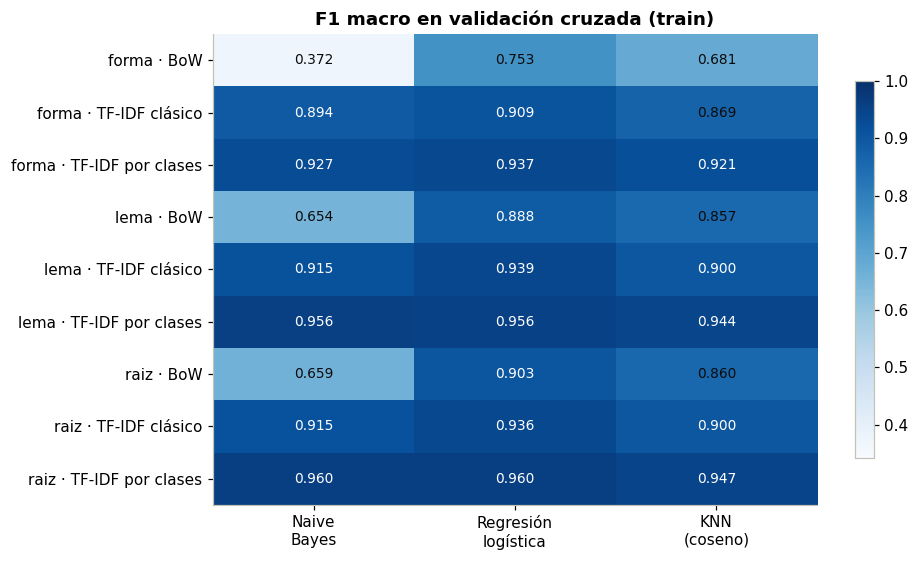

F1 media por representación: {'forma': 0.807, 'lema': 0.89, 'raiz': 0.894}
F1 media por vectorización:  {'BoW': 0.736, 'TF-IDF clásico': 0.909, 'TF-IDF por clases': 0.945}


In [24]:
# Mapa de calor: (representación, vectorización) x modelo
tabla = (res.pivot_table(index=["representación", "vectorización"], columns="modelo",
                         values="F1 macro (CV)")
         .reindex(index=[(r, v) for r in REPRESENTACIONES for v in VECTORIZADORES],
                  columns=list(MODELOS)))
fig, ax = plt.subplots(figsize=(9, 5.2))
im = ax.imshow(tabla.values, cmap="Blues", vmin=tabla.values.min() - 0.03, vmax=1,
               aspect="auto")
ax.set_xticks(range(tabla.shape[1]), [c.replace(" ", "\n", 1) for c in tabla.columns])
ax.set_yticks(range(tabla.shape[0]), [f"{r} · {v}" for r, v in tabla.index])
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        val = tabla.values[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=9,
                color="white" if val > tabla.values.mean() + 0.02 else "#0b0b0b")
ax.grid(False)
ax.set_title("F1 macro en validación cruzada (train)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

media_rep = res.groupby("representación")["F1 macro (CV)"].mean().round(3)
media_vec = res.groupby("vectorización")["F1 macro (CV)"].mean().round(3)
print("F1 media por representación:", media_rep.to_dict())
print("F1 media por vectorización: ", media_vec.to_dict())

**Lectura de los resultados:**

* **El modelo NLP aporta.** Las representaciones `lema` y `raiz` superan claramente a `forma`: al lematizar se juntan las variantes flexivas (*matĉo/matĉoj/matĉon*) y al quitar *stop-words* se elimina el ruido.
* **El TF-IDF por clases (el de clase) es la mejor vectorización**: da peso máximo a términos exclusivos de una clase (*rakedo, korbo, ofsajdo*) y anula los que aparecen en las tres (*ludo, teamo, ĉampiono*).
* Con TF-IDF por clases, **regresión logística y Naive Bayes quedan prácticamente empatados** y KNN algo por detrás (en alta dimensión y con vectores dispersos, la distancia entre párrafos cortos es poco informativa).
* **Naive Bayes con BoW funciona mal**: la BoW normalizada da frecuencias relativas muy pequeñas (< 1), y el modelo multinomial, pensado para recuentos, apenas las tiene en cuenta y acaba guiándose casi solo por la clase mayoritaria. Es un buen ejemplo de que la vectorización y el algoritmo deben elegirse juntos.

### 4.5 Ajuste de hiperparámetros y entrenamiento del modelo final

Sobre la mejor configuración se ajustan con `GridSearchCV` (misma validación cruzada) el `min_df` del vectorizador y la regularización del modelo. El mejor modelo se reentrena con todo el train.

In [25]:
mejor = res.iloc[0]
REP, VEC, MOD = mejor["representación"], mejor["vectorización"], mejor["modelo"]
print(f"Mejor configuración: representación={REP} | {VEC} | {MOD}")

REJILLAS = {"Naive Bayes": {"clf__alpha": [0.1, 0.3, 1.0]},
            "Regresión logística": {"clf__C": [1, 5, 20]},
            "KNN (coseno)": {"clf__n_neighbors": [5, 15, 30]}}
rejilla = {"vec__min_df": [1, 2, 3], **REJILLAS[MOD]}

X_rep = REPRESENTACIONES[REP]
X_train, X_test = subconjunto(X_rep, idx_train), subconjunto(X_rep, idx_test)
busqueda = GridSearchCV(Pipeline([("vec", VECTORIZADORES[VEC]()), ("clf", MODELOS[MOD]())]),
                        rejilla, cv=CV, scoring="f1_macro", n_jobs=1)
t0 = time.perf_counter()
busqueda.fit(X_train, y_train)
T_ENTRENAMIENTO = time.perf_counter() - t0
modelo = busqueda.best_estimator_            # ya reentrenado con todo el train
print(f"Mejores hiperparámetros: {busqueda.best_params_} | "
      f"F1 macro CV = {busqueda.best_score_:.3f} | tiempo: {T_ENTRENAMIENTO:.1f} s")
print(f"Dimensión de la representación tabular: {len(modelo.named_steps['vec'].get_feature_names_out())} términos")

Mejor configuración: representación=raiz | TF-IDF por clases | Regresión logística
Mejores hiperparámetros: {'clf__C': 1, 'vec__min_df': 1} | F1 macro CV = 0.962 | tiempo: 10.4 s
Dimensión de la representación tabular: 5626 términos


### 4.6 Evaluación en el conjunto de test

Accuracy: 0.960   |   F1 macro: 0.962

              precision    recall  f1-score   support

       Tenis      0.952     0.952     0.952       104
  Baloncesto      0.944     0.977     0.960        86
       Rugby      1.000     0.952     0.975        62

    accuracy                          0.960       252
   macro avg      0.965     0.960     0.962       252
weighted avg      0.961     0.960     0.960       252

Línea base sin NLP (formas en minúscula): F1 macro = 0.940 -> el modelo NLP mejora +2.2 puntos


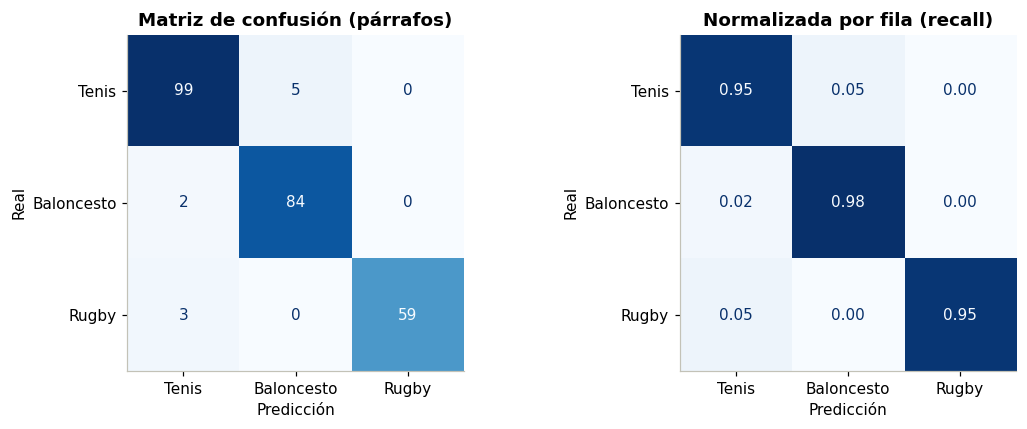

In [26]:
pred = modelo.predict(X_test)
acc, f1m = accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")
print(f"Accuracy: {acc:.3f}   |   F1 macro: {f1m:.3f}\n")
print(classification_report(y_test, pred, labels=list(CATEGORIAS),
                            target_names=[NOMBRES[c] for c in CATEGORIAS], digits=3))

# Línea base sin NLP con el mismo algoritmo y vectorización (para comparar)
base = Pipeline([("vec", VECTORIZADORES[VEC]()), ("clf", MODELOS[MOD]())])
base.fit(subconjunto(REPRESENTACIONES["forma"], idx_train), y_train)
f1_base = f1_score(y_test, base.predict(subconjunto(REPRESENTACIONES["forma"], idx_test)),
                   average="macro")
print(f"Línea base sin NLP (formas en minúscula): F1 macro = {f1_base:.3f} "
      f"-> el modelo NLP mejora {100 * (f1m - f1_base):+.1f} puntos")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for ax, norm, tit in [(axes[0], None, "Matriz de confusión (párrafos)"),
                      (axes[1], "true", "Normalizada por fila (recall)")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=list(CATEGORIAS), normalize=norm),
                           display_labels=[NOMBRES[c] for c in CATEGORIAS]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
    ax.set_title(tit)
    ax.grid(False)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

### 4.7 ¿Generaliza a artículos nuevos? Validación agrupada por artículo

En una partición aleatoria de párrafos, el train y el test pueden contener **párrafos del mismo artículo**, y el modelo puede acertar porque reconoce el artículo (nombres propios, estilo) y no el deporte. Para medirlo se usa `StratifiedGroupKFold`: todos los párrafos de un artículo caen en la misma partición. Es una estimación más realista (y más exigente) para textos nuevos, como las páginas web del apartado siguiente.

In [27]:
if df_meta is not None:
    grupos = df_meta["titulo"].to_numpy()
    cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    f1_grupos = cross_val_score(clone(modelo), X_rep, y, cv=cv_grupos, groups=grupos,
                                scoring="f1_macro")
    f1_aleat = cross_val_score(clone(modelo), X_rep, y, cv=CV, scoring="f1_macro")
    print(f"F1 macro, CV por párrafos aleatorios:  {f1_aleat.mean():.3f} ± {f1_aleat.std():.3f}")
    print(f"F1 macro, CV agrupada por artículo:    {f1_grupos.mean():.3f} ± {f1_grupos.std():.3f}")
else:
    print("Sin metadatos de artículo (no se pudo descargar el fichero _meta): se omite.")

F1 macro, CV por párrafos aleatorios:  0.960 ± 0.011
F1 macro, CV agrupada por artículo:    0.846 ± 0.080


La caída al agrupar por artículo confirma lo que se veía en la Fase 1: parte del rendimiento viene de reconocer artículos concretos (en rugby, muchos párrafos salen del artículo *Rugbeo*). Es la cifra que hay que esperar con textos realmente nuevos, y la principal limitación del dataset: **con más artículos distintos por clase mejoraría más que con un modelo más complejo**.

### 4.8 Interpretación: términos más discriminantes

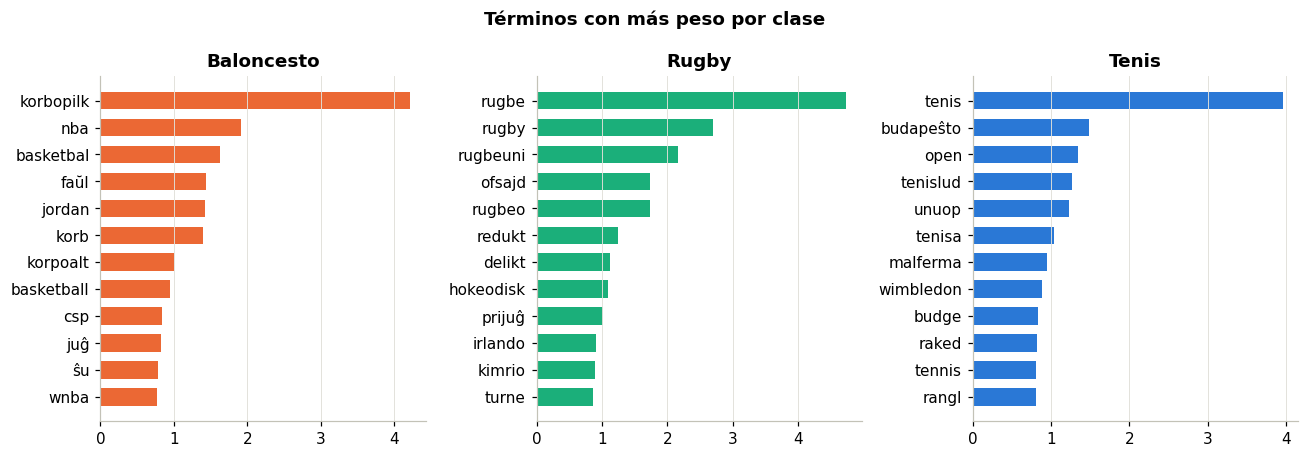

In [28]:
vec_final, clf_final = modelo.named_steps["vec"], modelo.named_steps["clf"]
nombres_t = vec_final.get_feature_names_out()
if hasattr(clf_final, "coef_"):
    pesos = clf_final.coef_                                  # regresión logística
elif hasattr(clf_final, "feature_log_prob_"):
    lp = clf_final.feature_log_prob_                         # NB: log P(t|c) - media
    pesos = lp - lp.mean(axis=0)
else:
    pesos = None

if pesos is not None:
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
    for ax, k, c in zip(axes, range(len(clf_final.classes_)), clf_final.classes_):
        top = np.argsort(pesos[k])[-12:]
        ax.barh(nombres_t[top], pesos[k][top], color=COLORES[c], height=0.65)
        ax.set_title(NOMBRES[c])
        ax.grid(axis="y", visible=False)
    fig.suptitle("Términos con más peso por clase", fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("El modelo elegido (KNN) no tiene pesos por término.")

### 4.9 Medida del ruido con el modelo

Se obtienen predicciones **fuera de muestra** para todo el dataset (`cross_val_predict`: cada párrafo lo predice un modelo que no lo ha visto). Si el modelo asigna un párrafo a una clase distinta de la heredada del artículo, ese párrafo es **candidato a ruido de etiquetado** (o a error del modelo). Se listan los de mayor confianza y se compara el acierto en párrafos que nombran su deporte y en los que no.

In [29]:
proba_oof = cross_val_predict(clone(modelo), X_rep, y, cv=CV, method="predict_proba")
clases_m = np.array(sorted(set(y)))          # orden de las columnas de predict_proba
pred_oof = clases_m[proba_oof.argmax(axis=1)]
conf_oof = proba_oof.max(axis=1)

ruido_df = pd.DataFrame({"class": y, "pred": pred_oof, "conf": conf_oof,
                         "tiene_clave": con_clave.to_numpy(), "text": df_dataset["text"]})
ruido_df["acierto"] = ruido_df["pred"] == ruido_df["class"]
ruido_df["sospechoso"] = ~ruido_df["acierto"]          # el modelo discrepa de la etiqueta heredada

tabla_ruido = ruido_df.groupby("class").agg(
    acierto_pct=("acierto", "mean"), discrepancias=("sospechoso", "sum"),
    discrepancias_pct=("sospechoso", "mean")).loc[list(CATEGORIAS)]
tabla_ruido[["acierto_pct", "discrepancias_pct"]] = (
    100 * tabla_ruido[["acierto_pct", "discrepancias_pct"]]).round(1)
display(tabla_ruido)

acc_clave = ruido_df.groupby("tiene_clave")["acierto"].mean()
print(f"Acierto en párrafos que nombran su deporte: {acc_clave.get(True, np.nan):.1%} | "
      f"en los que no: {acc_clave.get(False, np.nan):.1%}\n")
print("Discrepancias con más confianza (etiqueta heredada -> predicción):\n")
for _, f in ruido_df[ruido_df["sospechoso"]].sort_values("conf", ascending=False).head(5).iterrows():
    print(f"[{f['class']} -> {f['pred']} ({f['conf']:.2f})] {f['text'][:230]}\n")

,acierto_pct,discrepancias,discrepancias_pct
class,,,
teniso,97.1,15,2.9
korbopilkado,94.4,24,5.6
rugbeo,95.5,14,4.5


Acierto en párrafos que nombran su deporte: 98.7% | en los que no: 88.5%

Discrepancias con más confianza (etiqueta heredada -> predicción):

[rugbeo -> teniso (0.50)] Li estis invitita skribi mallongan rakonton por la Gakuŝuin literatura revuo, kaj li donis Hanazakari no mori (花ざかりの森, "Arbaro plenflorada"), en kiu la rakontanto priskribas la senton ke liaj prapatroj iel ankoraŭ vivas ene de li.

[teniso -> korbopilkado (0.49)] Marija Ŝarapova en novembro 2003 kontraktis kun la modelagentejo IMG. Ŝi havas sponsoran, reklaman kontrakton kun Nike, TAG Heuer, Prince kaj Motorola (2007).

[korbopilkado -> teniso (0.48)] Laŭ raporto de la Instituto por Diverseco kaj Etiko en Sporto ĉe la Universitato de Centra Florido, en la sezono de 2023, 63.8% de la ludantoj de la ligo estis afrik-usonaj aŭ nigrulaj, 19.1% estis blankuloj, 10.6% identiĝis kiel 

[korbopilkado -> teniso (0.47)] Nico Broekhuysen, amsterdamana instruisto serĉis ludon por siaj gelernantoj. En 1902, li ekkonis la «ringball» (

El modelo acierta casi siempre en los párrafos que nombran su deporte y claramente menos en los que no: ahí se concentra el ruido de heredar la etiqueta. Al leer las discrepancias se ve que muchas son **etiquetas dudosas** (párrafos genéricos o que hablan de otro deporte dentro de un artículo de la clase), no fallos del clasificador. Esto da una **cota del ruido** del dataset: como mucho, el porcentaje de discrepancias de la tabla.

In [30]:
T_FASES_2_3 = T_NLP + T_SELECCION + T_ENTRENAMIENTO
print(f"Tiempo de NLP + selección + entrenamiento: {T_FASES_2_3:.0f} s "
      f"(límite del enunciado: 300 s, sin GPU)")
assert T_FASES_2_3 < 300

Tiempo de NLP + selección + entrenamiento: 32 s (límite del enunciado: 300 s, sin GPU)


<a id="web"></a>
# 5. Clasificación de páginas web reales

Para probar el modelo en un entorno real se descargan páginas web en Esperanto con **web scraping** (`requests` + `BeautifulSoup`, temas 3.3-3.4) y se calcula la **probabilidad de cada categoría**.

Páginas elegidas (ninguna está en el dataset):

| Página | Sitio | Deporte esperado | Por qué |
|---|---|---|---|
| Coco Gauff gana el US Open | *Vikinovaĵoj* (Wikinoticias) | tenis | Otro sitio y otro género (noticia) |
| Kobe Bryant muere en un accidente de helicóptero | *Vikinovaĵoj* | baloncesto | Noticia que habla poco del deporte en sí |
| *Ĉampioneco de Ses Nacioj* (Seis Naciones) | *Vikipedio* | rugby | Artículo **reservado**: se excluyó del dataset en la Fase 1 |
| *Volejbalo* (voleibol) | *Vikipedio* | ninguno (control) | Deporte que no es ninguna de las clases: ¿qué hace el modelo? |

**Proceso para cada página:**

1. Comprobar `robots.txt` (convención ética del tema 3.4).
2. Descargar el HTML (User-Agent propio, *timeout* y reintentos). Si una URL falla se prueba la alternativa (versión móvil); si fallan todas se usa un **texto de respaldo** embebido, de modo que el cuaderno siempre termina.
3. Extraer los párrafos `<p>` del contenido principal, quitando tablas, referencias, *infoboxes* y navegación, y limpiarlos con la misma función de la Fase 1.
4. Clasificar cada párrafo y **agregar** las probabilidades de la página como media ponderada por el número de términos de cada párrafo (un párrafo largo informa más que una línea suelta).

In [31]:
PAGINAS_WEB = [
    {"nombre": "Vikinovaĵoj · Coco Gauff gana el US Open", "esperada": "teniso",
     "urls": ["https://eo.wikinews.org/wiki/Usona_tenisisto_Coco_Gauff_gajnis_la_tenisturniron_US_Open",
              "https://eo.m.wikinews.org/wiki/Usona_tenisisto_Coco_Gauff_gajnis_la_tenisturniron_US_Open"],
     "respaldo": "La usona tenisistino gajnis la finalon de la granda turniro kontraŭ sia "
                 "kontraŭulino post du serioj. Ŝi servis tre forte kaj venkis per sia rakedo "
                 "en la lasta ludo de la matĉo sur la tenisejo."},
    {"nombre": "Vikinovaĵoj · Muere Kobe Bryant", "esperada": "korbopilkado",
     "urls": ["https://eo.wikinews.org/wiki/Usona_korbopilkisto_Kobe_Bryant_kaj_ok_aliuloj_pereis_en_kra%C5%9Do_de_helikoptero",
              "https://eo.m.wikinews.org/wiki/Usona_korbopilkisto_Kobe_Bryant_kaj_ok_aliuloj_pereis_en_kra%C5%9Do_de_helikoptero"],
     "respaldo": "La fama korbopilkisto ludis dum dudek sezonoj en la teamo de Los-Anĝeleso "
                 "en la NBA. Li ĵetis la pilkon en la korbon kaj gajnis kvin ĉampionecojn kun "
                 "siaj samteamanoj."},
    {"nombre": "Vikipedio · Ĉampioneco de Ses Nacioj", "esperada": "rugbeo",
     "urls": ["https://eo.wikipedia.org/wiki/%C4%88ampioneco_de_Ses_Nacioj",
              "https://eo.m.wikipedia.org/wiki/%C4%88ampioneco_de_Ses_Nacioj"],
     "respaldo": "La ĉampioneco estas ĉiujara rugbea konkurso inter la naciaj teamoj de Anglio, "
                 "Francio, Irlando, Italio, Kimrio kaj Skotlando. La rugbeistoj portas la ovoforman "
                 "pilkon trans la linion por marki provon."},
    {"nombre": "Vikipedio · Volejbalo (control)", "esperada": None,
     "urls": ["https://eo.wikipedia.org/wiki/Volejbalo",
              "https://eo.m.wikipedia.org/wiki/Volejbalo"],
     "respaldo": "Volejbalo estas teama sporto en kiu du teamoj de ses ludantoj estas apartigitaj "
                 "per reto. Ĉiu teamo provas igi la pilkon tuŝi la grundon de la kontraŭa flanko."},
]

ELEMENTOS_A_QUITAR = ["script", "style", "table", "sup", "figure", "nav", "footer",
                      ".reference", ".mw-editsection", ".navbox", ".infobox", ".metadata",
                      ".toc", "#toc", ".thumb", ".hatnote", ".mw-references-wrap"]


def permitido_por_robots(url, agente=HEADERS["User-Agent"]):
    """Consulta robots.txt del sitio. Si no se puede leer, se asume permitido
    (es una convención; se deja constancia en la salida)."""
    partes = urlparse(url)
    robots_url = f"{partes.scheme}://{partes.netloc}/robots.txt"
    try:
        r = requests.get(robots_url, headers=HEADERS, timeout=10)
        if r.status_code != 200:
            return True, "robots.txt no disponible"
        rp = RobotFileParser()
        rp.parse(r.text.splitlines())
        return rp.can_fetch(agente, url), "robots.txt consultado"
    except requests.RequestException:
        return True, "robots.txt no accesible"


def descargar_html(url, reintentos=3):
    for intento in range(reintentos):
        try:
            r = requests.get(url, headers=HEADERS, timeout=20)
            r.raise_for_status()
            r.encoding = r.encoding or "utf-8"
            return r.text
        except requests.RequestException as e:
            error = e
            time.sleep(1 + intento)
    raise ConnectionError(f"No se pudo descargar {url}: {type(error).__name__}")


def extraer_parrafos_html(html, min_palabras=8):
    """Párrafos de texto del contenido principal de una página HTML."""
    soup = BeautifulSoup(html, "html.parser")
    contenido = (soup.select_one("#mw-content-text .mw-parser-output")
                 or soup.find("main") or soup.find("article") or soup.body or soup)
    for selector in ELEMENTOS_A_QUITAR:
        for el in contenido.select(selector):
            el.decompose()
    titulo = soup.title.get_text(strip=True) if soup.title else ""
    # Solo los <p> hijos directos del contenido: los que están dentro de cajas
    # (plantillas, avisos de traducción...) no son el texto de la página.
    nodos = contenido.find_all("p", recursive=False) or contenido.find_all("p")
    parrafos = [limpiar_parrafo(p.get_text(" ")) for p in nodos]
    return titulo, [p for p in parrafos if len(p.split()) >= min_palabras]


def obtener_pagina(pagina):
    """Intenta cada URL de la página; si todas fallan, usa el texto de respaldo."""
    for url in pagina["urls"]:
        permitido, nota = permitido_por_robots(url)
        if not permitido:
            print(f"  ⚠ robots.txt no permite {url}")
            continue
        try:
            titulo, parrafos = extraer_parrafos_html(descargar_html(url))
            if parrafos:
                return {"fuente": url, "titulo": titulo, "parrafos": parrafos, "nota": nota}
        except ConnectionError as e:
            print(f"  ✗ {e}")
    return {"fuente": "texto de respaldo (web no disponible)", "titulo": pagina["nombre"],
            "parrafos": [pagina["respaldo"]], "nota": "-"}


def clasificar_parrafos(parrafos):
    """Probabilidades por párrafo y agregadas (media ponderada por nº de términos)."""
    X = [terminos(nlp(p), REP) for p in parrafos]
    proba = modelo.predict_proba(X)
    pesos = np.array([max(len(x), 1) for x in X], dtype=float)
    return proba, (proba * pesos[:, None]).sum(axis=0) / pesos.sum()


CLASES_MODELO = list(modelo.classes_)
UMBRAL_DOMINIO = 0.5    # por debajo: la página no parece de ninguna de las 3 clases
filas_web, detalle_web = [], {}
for pagina in PAGINAS_WEB:
    print(f"▶ {pagina['nombre']}")
    info = obtener_pagina(pagina)
    proba_parr, proba_pag = clasificar_parrafos(info["parrafos"])
    detalle_web[pagina["nombre"]] = (info, proba_parr)
    print(f"  fuente: {info['fuente'][:95]} | {len(info['parrafos'])} párrafos | {info['nota']}")
    predicha = CLASES_MODELO[int(proba_pag.argmax())]
    fila = {"página": pagina["nombre"], "esperada": pagina["esperada"] or "—",
            "predicha": predicha,
            "decisión": predicha if proba_pag.max() >= UMBRAL_DOMINIO else "desconocido"}
    fila.update({f"P({c})": p for c, p in zip(CLASES_MODELO, proba_pag)})
    filas_web.append(fila)

df_web = pd.DataFrame(filas_web)
display(df_web.style.format({f"P({c})": "{:.1%}" for c in CLASES_MODELO})
        .hide(axis="index"))

▶ Vikinovaĵoj · Coco Gauff gana el US Open
  fuente: https://eo.wikinews.org/wiki/Usona_tenisisto_Coco_Gauff_gajnis_la_tenisturniron_US_Open | 4 párrafos | robots.txt consultado
▶ Vikinovaĵoj · Muere Kobe Bryant
  fuente: https://eo.wikinews.org/wiki/Usona_korbopilkisto_Kobe_Bryant_kaj_ok_aliuloj_pereis_en_kra%C5%9D | 5 párrafos | robots.txt consultado
▶ Vikipedio · Ĉampioneco de Ses Nacioj
  fuente: https://eo.wikipedia.org/wiki/%C4%88ampioneco_de_Ses_Nacioj | 4 párrafos | robots.txt consultado
▶ Vikipedio · Volejbalo (control)
  fuente: https://eo.wikipedia.org/wiki/Volejbalo | 9 párrafos | robots.txt consultado


página,esperada,predicha,decisión,P(korbopilkado),P(rugbeo),P(teniso)
Vikinovaĵoj · Coco Gauff gana el US Open,teniso,teniso,teniso,11.6%,9.5%,78.9%
Vikinovaĵoj · Muere Kobe Bryant,korbopilkado,korbopilkado,korbopilkado,66.8%,14.0%,19.2%
Vikipedio · Ĉampioneco de Ses Nacioj,rugbeo,rugbeo,rugbeo,13.5%,73.4%,13.1%
Vikipedio · Volejbalo (control),—,teniso,desconocido,34.3%,24.9%,40.8%


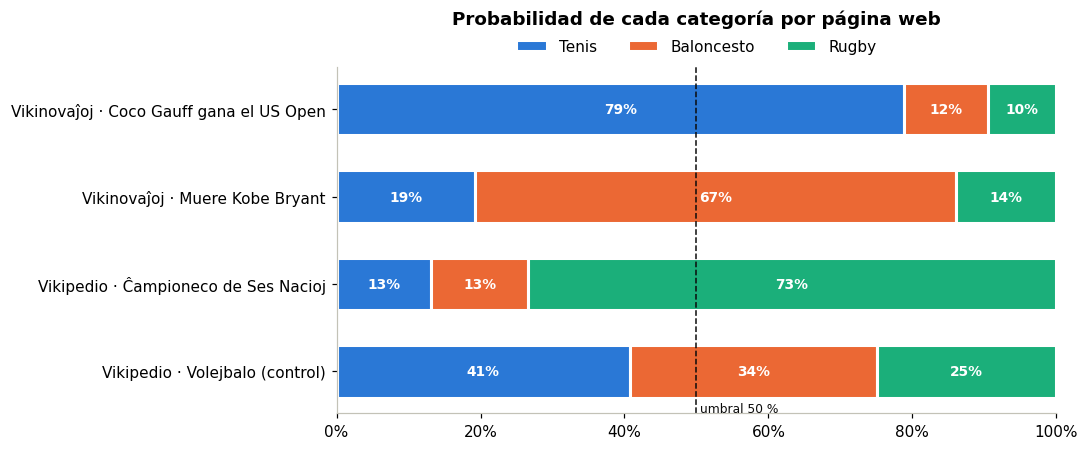

In [32]:
# Probabilidad de cada categoría por página (barra 100 % apilada)
fig, ax = plt.subplots(figsize=(10, 0.75 * len(df_web) + 1.2))
izquierda = np.zeros(len(df_web))
orden = list(CATEGORIAS)
for c in orden:
    valores = df_web[f"P({c})"].to_numpy()
    ax.barh(df_web["página"], valores, left=izquierda, color=COLORES[c],
            edgecolor="white", linewidth=2, height=0.6, label=NOMBRES[c])
    for i, (v, l) in enumerate(zip(valores, izquierda)):
        if v >= 0.08:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white",
                    fontsize=9, fontweight="bold")
    izquierda += valores
ax.set_xlim(0, 1)
ax.axvline(UMBRAL_DOMINIO, color="#0b0b0b", ls="--", lw=1)
ax.text(UMBRAL_DOMINIO + 0.005, len(df_web) - 0.58, "umbral 50 %", fontsize=8, color="#0b0b0b", va="center")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.grid(False)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title("Probabilidad de cada categoría por página web", pad=28)
plt.tight_layout()
plt.show()

In [33]:
# Detalle párrafo a párrafo de la noticia de baloncesto: ¿qué párrafos deciden?
info, proba_parr = detalle_web["Vikinovaĵoj · Muere Kobe Bryant"]
detalle = pd.DataFrame(proba_parr, columns=[f"P({c})" for c in CLASES_MODELO])
detalle.insert(0, "párrafo", [p[:110] + ("…" if len(p) > 110 else "") for p in info["parrafos"]])
display(detalle.style.format({f"P({c})": "{:.0%}" for c in CLASES_MODELO})
        .background_gradient(cmap="Blues", vmin=0, vmax=1,
                             subset=[f"P({c})" for c in CLASES_MODELO]).hide(axis="index"))

párrafo,P(korbopilkado),P(rugbeo),P(teniso)
"La 26-an de januaro, en Kalifornio ( Usono) kraŝis helikoptero transportinta la korbopilkiston Kobe Bryant. Ĉi…",82%,8%,10%
"La kraŝo okazis en la urbeto Calabasas en Kalifornio, proksime al Los-Anĝeleso, je proksimume la 10-a horo mat…",36%,26%,38%
"Laŭ tvito de Adrian Wojnarowski, sportĵurnalisto de ESPN, Bryant kaj Gianna estis survoje al korbopilka maĉo. …",88%,7%,5%
"Kobe Bryant, ofte konsiderata kiel legendo de korbopilkado, aliĝis al la Nacia Korbopilka Asocio (NBA) en la j…",97%,1%,1%
"Aŭtoritatoj de Calabasas anoncis per Tvitero ke du registaraj organizaĵoj, la Federacia Aviada Administracio (…",34%,27%,40%


**Análisis:**

* Las páginas de tenis, baloncesto y rugby se clasifican en su categoría, aunque dos de ellas vienen de **otro sitio** (Wikinoticias) y de **otro género** (noticias), distintos de los del entrenamiento.
* En la noticia de Kobe Bryant, los párrafos sobre el **accidente** (helicóptero, víctimas) tienen probabilidades más repartidas; los que hablan de su carrera (*NBA, Lakers, korbopilkisto*) son los que deciden. Agregar por página hace la predicción más robusta que con un párrafo suelto.
* **Voleibol (control)** no es ninguna de las tres clases, pero un clasificador siempre elige una. Lo relevante es que su probabilidad máxima sea **mucho más baja y repartida** que en las páginas de las tres clases. Por eso se añade la columna `decisión`: si ninguna clase supera `UMBRAL_DOMINIO = 0.5`, la página se marca como *desconocido* (fuera de dominio).

Función auxiliar para probar textos o URLs nuevos (útil en la defensa):

In [34]:
def clasificar_texto(texto):
    """Probabilidad de cada categoría para un texto libre en Esperanto."""
    parrafos = [p for p in re.split(r"\n\s*\n|\n", texto) if p.strip()] or [texto]
    _, proba = clasificar_parrafos([limpiar_parrafo(p) for p in parrafos])
    return {NOMBRES[c]: round(float(p), 3) for c, p in zip(CLASES_MODELO, proba)}


def clasificar_url(url):
    """Descarga una página (con su comprobación de robots.txt) y la clasifica."""
    info = obtener_pagina({"nombre": url, "urls": [url], "respaldo": ""})
    if not info["parrafos"] or not info["parrafos"][0]:
        return "No se pudo obtener texto de la página"
    _, proba = clasificar_parrafos(info["parrafos"])
    return {NOMBRES[c]: round(float(p), 3) for c, p in zip(CLASES_MODELO, proba)}


for frase in ["La tenisisto servis kaj gajnis la unuan serion per sia nova rakedo.",
              "La centro ĵetis la pilkon kaj trafis la korbon en la lasta sekundo.",
              "La skrumo puŝis forte kaj la flankulo markis provon post la ofsajdo.",
              "La teamo venkis en la finalo antaŭ dek mil spektantoj."]:
    print(f"{frase}\n   -> {clasificar_texto(frase)}")

La tenisisto servis kaj gajnis la unuan serion per sia nova rakedo.
   -> {'Baloncesto': 0.005, 'Rugby': 0.005, 'Tenis': 0.99}
La centro ĵetis la pilkon kaj trafis la korbon en la lasta sekundo.
   -> {'Baloncesto': 0.788, 'Rugby': 0.099, 'Tenis': 0.113}
La skrumo puŝis forte kaj la flankulo markis provon post la ofsajdo.
   -> {'Baloncesto': 0.137, 'Rugby': 0.71, 'Tenis': 0.153}
La teamo venkis en la finalo antaŭ dek mil spektantoj.
   -> {'Baloncesto': 0.348, 'Rugby': 0.28, 'Tenis': 0.372}


<a id="conclusiones"></a>
# 6. Conclusiones

In [35]:
print("RESUMEN DE RESULTADOS")
print(f"  Dataset:  {len(df_dataset)} párrafos | " +
      " | ".join(f"{c}: {n}" for c, n in df_dataset['class'].value_counts().items()) +
      f" | origen: {ORIGEN_DATASET[:60]}")
print(f"  NLP:      precisión POS {gold_ok_pos / total:.1%}, lema {gold_ok_lema / total:.1%} (gold standard)")
print(f"  Modelo:   {REP} + {VEC} + {MOD} {busqueda.best_params_}")
print(f"  Test:     accuracy {acc:.3f} | F1 macro {f1m:.3f} | sin NLP: F1 {f1_base:.3f}")
print(f"  Web:      " + " | ".join(f"{f['página'].split('·')[-1].strip()}: {f['decisión']}"
                                     for f in filas_web))
print(f"  Tiempo total de ejecución del cuaderno: {time.perf_counter() - T_INICIO:.0f} s")

RESUMEN DE RESULTADOS
  Dataset:  1260 párrafos | teniso: 519 | korbopilkado: 432 | rugbeo: 309 | origen: https://raw.githubusercontent.com/luuciaamartinez/mineria-te
  NLP:      precisión POS 99.1%, lema 99.1% (gold standard)
  Modelo:   raiz + TF-IDF por clases + Regresión logística {'clf__C': 1, 'vec__min_df': 1}
  Test:     accuracy 0.960 | F1 macro 0.962 | sin NLP: F1 0.940
  Web:      Coco Gauff gana el US Open: teniso | Muere Kobe Bryant: korbopilkado | Ĉampioneco de Ses Nacioj: rugbeo | Volejbalo (control): desconocido
  Tiempo total de ejecución del cuaderno: 45 s


### Conclusiones

1. **Dataset (Fase 1).** Se obtuvo un dataset de párrafos limpios en Esperanto con las tres clases por encima de 300 párrafos, de forma automática y reproducible (crawling de categorías + búsqueda del API) y publicado en GitHub. El estudio previo de viabilidad fue clave: obligó a cambiar golf por baloncesto y a descubrir que la categoría se llama *Korbopilkado*.
2. **Ruido.** Heredar la etiqueta del artículo introduce un ruido apreciable: más de un 25 % de los párrafos no nombra su deporte, y el modelo encuentra párrafos con etiqueta dudosa. Se ha reconocido, medido de dos formas y comentado, sin eliminarlo para no sesgar el dataset hacia lo fácil.
3. **Modelo NLP (Fase 2).** La regularidad del Esperanto permite un analizador por reglas preciso (terminaciones, correlativos, participios, nombres propios) con una API tipo spaCy y pruebas automáticas. Su utilidad se demuestra en la Fase 3: lematizar y filtrar *stop-words* mejora el clasificador respecto a usar las palabras tal cual.
4. **Clasificación (Fase 3).** El **TF-IDF por clases visto en clase** fue la mejor vectorización, con regresión logística y Naive Bayes casi empatados como algoritmo. El resultado en test es alto, pero la validación agrupada por artículo da una cifra más realista para textos nuevos, y las páginas web reales (de otro sitio y género) se clasifican correctamente.

### Limitaciones y trabajo futuro

* **Pocos artículos distintos por clase** (sobre todo en rugby): es la principal limitación. Se podrían añadir otras fuentes en Esperanto (Vikinovaĵoj, revistas) o artículos enlazados desde los de la categoría.
* **Clasificación cerrada:** el modelo siempre elige una de las tres clases. Para uso real convendría una clase "otro" o un umbral de confianza.
* El analizador no hace **análisis sintáctico** ni desambiguación por contexto (fuera del alcance del curso).

### Referencias

* Enunciado y transparencias de la asignatura (temas 2.2-2.4 y 3.1-3.6), prof. Javier Paris.
* Repositorio guía `jparisu/nlp-esperantilo`: gramática del Esperanto y `vortoj.json` (Apache-2.0).
* API de MediaWiki: `list=categorymembers`, `list=search`, `prop=extracts` — eo.wikipedia.org. Textos de Wikipedia y Wikinoticias bajo licencia CC BY-SA.